# Aprendizaje Automático I

## Trabajo Práctico: Predicción de lluvia en Australia

### Facultad de Ciencias Exactas, Ingeniería y Agrimensura (FCEIA) - Universidad Nacional de Rosario (UNR)

**Integrantes:** Tomás Gimbatti y Valentino Longo 

---

### Contenidos

1. Configuración del entorno
2. Carga e inspección estructural del dataset
3. División train / test
4. Gestión de datos nulos y duplicados

## 1. Configuración del entorno

In [109]:
# Importamos las librerías necesarias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Semilla fija para que los resultados sean reproducibles
RANDOM_STATE = 42

# Contador para referenciar a los gráficos
N_FIG = 1

## 2. Carga e inspección estructural del dataset

**Diccionario de variables**

* **Date:** (Cualitativa) Fecha de la observación.
* **Location:** (Cualitativa) Nombre de la estación meteorológica. 
* **MinTemp:** (Continua) Temperatura mínima registrada en grados Celsius (°C) en las 24 horas previas a las 9:00 AM.
* **MaxTemp:** (Continua) Temperatura máxima registrada en grados Celsius (°C) en las 24 horas previas a las 9:00 AM.
* **Rainfall:** (Continua) Cantidad de lluvia recolectada (en milímetros) durante las 24 horas previas a las 9:00 AM.
* **Evaporation:** (Continua) Medida en milímetros (mm) acumulados en las 24 horas previas a las 9:00 AM.
* **Sunshine:** (Continua)  Número total de horas de sol brillante registradas durante todo el día.
* **WindGustDir:** (Cualitativa) Dirección de la ráfaga de viento más fuerte ocurrida en las 24 horas hasta la medianoche.
* **WindGustSpeed:** (Cualitativa) Velocidad de la ráfaga de viento más fuerte en kilómetros por hora (km/h) en las 24 horas anteriores a la medianoche.
* **WindDir9am:** (Cualitativa)  Dirección del viento registrada a las 9:00 AM.
* **WindDir3pm:** (Cualitativa)  Dirección del viento registrada a las 3:00 PM
* **WindSpeed9am:** (Cualitativa) Velocidad del viento en km/h medida como el promedio de los 10 minutos anteriores a las 9:00 AM.
* **WindSpeed3pm:** (Cualitativa) Velocidad del viento en km/h medida como el promedio de los 10 minutos anteriores a las 3:00 PM.
* **Humidity9am:** (Continua) Porcentaje de humedad relativa registrado a las 9:00 AM.
* **Humidity3pm:** (Continua) Porcentaje de humedad relativa registrado a las 3:00 PM.
* **Pressure9am:** (Continua) Presión atmosférica reducida al nivel del mar medida en hectopascales (hPa) a las 9:00 AM.
* **Pressure3pm:** (Continua) Presión atmosférica reducida al nivel del mar medida en hectopascales (hPa) a las 3:00 PM.
* **Cloud9am:** (Discreta) Fracción de cielo cubierta por nubes a las 9:00 AM medido en octas (octavos de cielo cubierto).
* **Cloud3pm:** (Discreta) Fracción de cielo cubierta por nubes a las 3:00 PM medido en octas (octavos de cielo cubierto).
* **Temp9am:** (Continua) Temperatura en grados Celsius (°C) medida a las 9:00 AM.
* **Temp3pm:** (Continua) Temperatura en grados Celsius (°C) medida a las 3:00 PM.
* **RainToday:** (Cualitativa Dicotómica) Toma el valor "Yes" si la precipitación (Rainfall) en las 24 horas previas a las 9:00 AM supera 1 mm, y "No" en caso contrario.
* **RainTomorrow:** (Cualitativa Dicotómica) Se calcula directamente a partir de la variable (RainfallTomorrow), si la lluvia del día de mañana supera 1.0 mm, toma el valor de "Yes" y "No" en caso contrario.
* **RainfallTomorrow:** (Cuantitativa) Cantidad de lluvia registrada al día siguiente en milímetros (mm).

In [110]:
# Lectura del archivo .csv
df = pd.read_csv("weatherAUS_2026C2.csv")

In [111]:
# Mostramos información del dataset sobre todas las columnas
print(f'Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas\n')
resumen = pd.DataFrame({
    "Cantidad de no nulos": df.notna().sum(),
    "Tipo de dato": df.dtypes
})

resumen.index.name = "Columna"
display(resumen)

Dimensiones del dataset: 145412 filas x 25 columnas



,Cantidad de no nulos,Tipo de dato
Columna,,
Unnamed: 0,145412,int64
Date,145412,str
Location,145412,str
MinTemp,143928,float64
MaxTemp,144159,float64
Rainfall,142152,float64
Evaporation,82658,float64
Sunshine,75616,float64
WindGustDir,135096,str


In [112]:
df.head()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


In [113]:
df.tail()

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
145407,145454,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,...,26.5,1024.8,1021.2,NaN,NaN,10.1,21.6,No,No,0.0
145408,145455,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,...,24.7,1024.3,1020.5,NaN,NaN,11.1,21.5,No,No,0.0
145409,145456,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,...,21.4,1023.3,1018.4,NaN,NaN,11.8,24.5,No,No,0.0
145410,145457,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,...,23.7,1021.0,1016.0,NaN,NaN,12.0,26.9,No,No,0.0
145411,145458,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,...,27.1,1019.8,1016.2,3.0,2.0,14.7,26.8,No,No,0.0


In [114]:
# Eliminamos la primera columna y la de RainFallTomorrow
df_limpio = df.drop(columns=["Unnamed: 0", "RainfallTomorrow"], errors="ignore").copy()


Decidimos eliminar "Unnamed: 0" ya que era una variable que no nos aportaba nada al actuar como índice. También eliminamos "RainfallTomorrow" porque generaría una fuga de datos al contener información sobre la precipitación del día de mañana que con datos nuevos esa variable no se conoce ya que no se puede medir la precipitación de un día que todavía no sucedió. 

In [115]:
# Mostramos 5 registros aleatorios con la columna eliminada
df_limpio.sample(5, random_state=RANDOM_STATE)

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
36428,2017-03-27,SydneyAirport,20.7,28.9,0.0,5.8,11.0,NE,52.0,NNW,...,73.9,67.2,1016.8,1011.9,1.0,1.0,23.8,27.2,No,No
131530,2013-06-28,Hobart,5.2,13.6,0.0,1.0,5.0,NW,30.0,NNW,...,75.0,59.8,1021.2,1021.9,NaN,NaN,7.4,12.1,No,No
30576,2009-03-16,Sydney,16.5,27.0,0.4,6.8,10.8,NaN,NaN,W,...,40.6,29.5,1011.1,1008.1,1.0,0.0,19.0,26.4,No,No
23078,2014-08-17,NorfolkIsland,10.1,17.7,0.6,3.0,6.1,E,36.0,E,...,59.4,57.2,1023.5,1020.5,7.0,7.0,14.6,15.8,No,No
123321,2016-03-12,Perth,18.4,33.2,0.0,8.4,11.2,SSW,40.0,ESE,...,56.0,47.6,1015.9,1012.2,0.0,0.0,25.4,28.7,No,No


In [116]:
# Separamos las variables por tipo
cols_numericas = df_limpio.select_dtypes(include=[np.number]).columns.tolist()
cols_discretas = ['Cloud3pm', 'Cloud9am']
cols_continuas = [col for col in cols_numericas if col not in cols_discretas]
cols_categoricas = df_limpio.select_dtypes(include=['str']).columns.tolist()

print(f'Variables numéricas ({len(cols_numericas)}): {cols_numericas}')
print(f'Variables categóricas ({len(cols_categoricas)}): {cols_categoricas}')

Variables numéricas (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Variables categóricas (7): ['Date', 'Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'RainTomorrow']


## 3. División train / test

Dividimos el dataset en entrenamiento (80%) y prueba (20%) antes de imputar y antes de seguir con el análisis. Todos los procedimientos que aprenden algo de los datos (la imputación, el escalado, los modelos) se ajustan únicamente con el conjunto de entrenamiento. Si el imputador se ajustara con todos los datos, la información del test se filtraría al modelo (data leakage) y la evaluación final dejaría de ser una medición honesta sobre datos nunca vistos.

Los registros con valores faltantes se reparten entre los dos conjuntos como cualquier otro registro, y se imputan después de la división. 

No divimos en train y test de manera aleatoria, ya que en ese caso podríamos predecir si el lunes llovío con la información entrenada del martes siguiente, generando fuga de datos. Lo que hicimos fue ordenar los datos por fecha y obtuvimos una fecha de corte para dividir al conjunto de datos en aproximadamente 80/20.

In [117]:
# Realizamos la división train-test buscando la fecha cuyo corte deja la proporción de filas más cercana a 80/20.
df_limpio["Date"] = pd.to_datetime(df_limpio["Date"], errors="raise")

filas_por_fecha = df_limpio.groupby("Date", sort=True).size()
filas_objetivo_train = 0.80 * len(df_limpio)
fecha_corte = (filas_por_fecha.cumsum() - filas_objetivo_train).abs().idxmin()

train = df_limpio.loc[df_limpio["Date"] <= fecha_corte].copy()
test = df_limpio.loc[df_limpio["Date"] > fecha_corte].copy()

print(f"Fecha de corte: {fecha_corte.date()}")
print(f"Train: {len(train):,} filas ({len(train) / len(df_limpio):.2%})")
print(f"Test:  {len(test):,} filas ({len(test) / len(df_limpio):.2%})")

Fecha de corte: 2015-11-08
Train: 116,306 filas (79.98%)
Test:  29,106 filas (20.02%)


In [118]:
X_train = train.drop(columns=["RainTomorrow"])
y_train = train["RainTomorrow"]

X_test = test.drop(columns=["RainTomorrow"])
y_test = test["RainTomorrow"]

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape} | y_test:  {y_test.shape}")

X_train: (116306, 22) | y_train: (116306,)
X_test:  (29106, 22) | y_test:  (29106,)


## 4. Gestión de datos nulos y duplicados

In [119]:
# Reporte de valores nulos por columna
nulos = X_train.isnull().sum()
pct_nulos = (nulos / len(X_train)) * 100

reporte_nulos = pd.DataFrame({
    'Nulos': nulos,
    'Porcentaje (%)': pct_nulos.round(2),
    'Tipo': X_train.dtypes
})

print('Reporte de Valores Nulos:')
print('=' * 50)
print(reporte_nulos)
print(f'\nTotal de celdas con nulos: {nulos.sum()} ({nulos.sum() / X_train.size * 100:.2f}% del dataset)')

Reporte de Valores Nulos:
               Nulos  Porcentaje (%)            Tipo
Date               0            0.00  datetime64[us]
Location           0            0.00             str
MinTemp         1085            0.93         float64
MaxTemp          881            0.76         float64
Rainfall        2606            2.24         float64
Evaporation    45916           39.48         float64
Sunshine       50076           43.06         float64
WindGustDir     8545            7.35             str
WindGustSpeed   8482            7.29         float64
WindDir9am      8871            7.63             str
WindDir3pm      2815            2.42             str
WindSpeed9am    1568            1.35         float64
WindSpeed3pm    1761            1.51         float64
Humidity9am     2115            1.82         float64
Humidity3pm     2328            2.00         float64
Pressure9am    11866           10.20         float64
Pressure3pm    11832           10.17         float64
Cloud9am       43110

In [120]:
# Observamos la cantidad de valores nulos por registro
nulos_por_registro = X_train.isna().sum(axis=1).value_counts().sort_index()

resumen_nulos = nulos_por_registro.rename_axis(
    "Cantidad de valores nulos"
).reset_index(name="Cantidad de registros")

display(resumen_nulos)

,Cantidad de valores nulos,Cantidad de registros
0,0,49344
1,1,8823
2,2,14112
3,3,6784
4,4,21288
5,5,2904
6,6,8335
7,7,1617
8,8,781
9,9,168


In [121]:
# Porcentaje de registros que presentan algún valor nulo
nulos = resumen_nulos[resumen_nulos["Cantidad de valores nulos"] >= 1]["Cantidad de registros"].sum()
porcentaje_nulos = (nulos / len(X_train)) * 100
print(f"Porcentaje de registros que presentan algún valor nulo: {porcentaje_nulos.round(2)}%")

Porcentaje de registros que presentan algún valor nulo: 57.57%


In [122]:
# Analizamos porcentaje de datos duplicados
n_duplicados = X_train.duplicated().sum()
print(f'Registros duplicados: {n_duplicados} ({(n_duplicados / len(X_train) * 100).round(2)}%)')

Registros duplicados: 0 (0.0%)


In [123]:
# Eliminamos los registros con target nulo (en X_train e y_train a la vez)

registros_antes = len(X_train)
mascara_target = y_train.notna()          # True donde el target está presente

X_train = X_train.loc[mascara_target].copy()
y_train = y_train.loc[mascara_target].copy()

eliminados = registros_antes - len(y_train)

valores_a_imputar = X_train.isna().sum().sum()
registros_con_faltantes = X_train.isna().any(axis=1).sum()

print(f"Registros eliminados por target nulo: {eliminados:,}")
print(f"Registros restantes: {len(y_train):,} de {registros_antes:,}")
print(f"Valores faltantes en variables predictoras por imputar: {valores_a_imputar:,}")
print(f"Registros restantes con al menos un faltante: {registros_con_faltantes:,}")

Registros eliminados por target nulo: 2,605
Registros restantes: 113,701 de 116,306
Valores faltantes en variables predictoras por imputar: 235,603
Registros restantes con al menos un faltante: 64,491


Elegimos eliminar los registros con valores nulso en el target porque sin variable objetivo, un registro no sirve para entrenar (no hay error que calcular) ni para evaluar (no hay valor real contra el cual comparar la predicción). Tampoco corresponde imputar el target: sería inventar la respuesta que el modelo debe aprender.

# 5. Métricas de variables cuantitativas

In [124]:
X_train.describe()

,Date,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,113701,113233.000000,113478.000000,112574.000000,69366.000000,65188.000000,106029.000000,112498.000000,112303.000000,112226.000000,112009.000000,102639.000000,102674.000000,72377.000000,71086.000000,112895.000000,112718.000000
mean,2012-05-22 21:34:18.251026,11.949036,22.957778,2.345968,5.300033,7.587811,40.063662,14.055797,18.685253,68.810848,51.530810,1017.799328,1015.410490,4.330436,4.430000,16.760314,21.474769
min,2007-11-01 00:00:00,-9.700000,-3.900000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.300000,980.000000,0.000000,0.000000,-6.500000,-4.800000
25%,2010-08-01 00:00:00,7.400000,17.800000,0.000000,2.600000,4.800000,31.000000,7.000000,12.000000,56.900000,36.700000,1013.000000,1010.600000,1.000000,2.000000,12.100000,16.500000
50%,2012-05-22 00:00:00,11.800000,22.300000,0.000000,4.600000,8.400000,38.000000,13.000000,18.000000,69.800000,51.900000,1017.800000,1015.400000,5.000000,5.000000,16.500000,20.900000
75%,2014-03-18 00:00:00,16.600000,27.900000,0.800000,7.200000,10.600000,48.000000,19.000000,24.000000,83.100000,65.600000,1022.600000,1020.200000,7.000000,7.000000,21.300000,26.200000
max,2015-11-08 00:00:00,34.100000,49.100000,371.000000,82.400000,14.300000,135.000000,88.000000,86.000000,100.000000,100.000000,1041.200000,1039.800000,9.000000,9.000000,39.800000,46.900000
std,NaN,6.393345,7.051411,8.493096,3.988394,3.772337,13.666441,8.977627,8.911121,19.074452,20.775919,7.141179,7.068966,2.877412,2.704247,6.463057,6.889246


La descripción de las 113.701 filas de train muestra diferencias importantes entre variables y entre sus cantidades observadas, por lo que los valores nulos no son uniformes. En Rainfall, la media es 2,35 y la mediana es 0, con un máximo de 371; esta separación refleja una distribución con muchos registros sin lluvia y algunos acumulados muy altos. Cloud9am y Cloud3pm todavía contienen el valor 9 en esta etapa previa a la imputación, lo que conviene tratar como valor inválido y no como una categoría meteorológica válida.

# 6. Histogramas y estimación de densidad de las variables cuantitativas

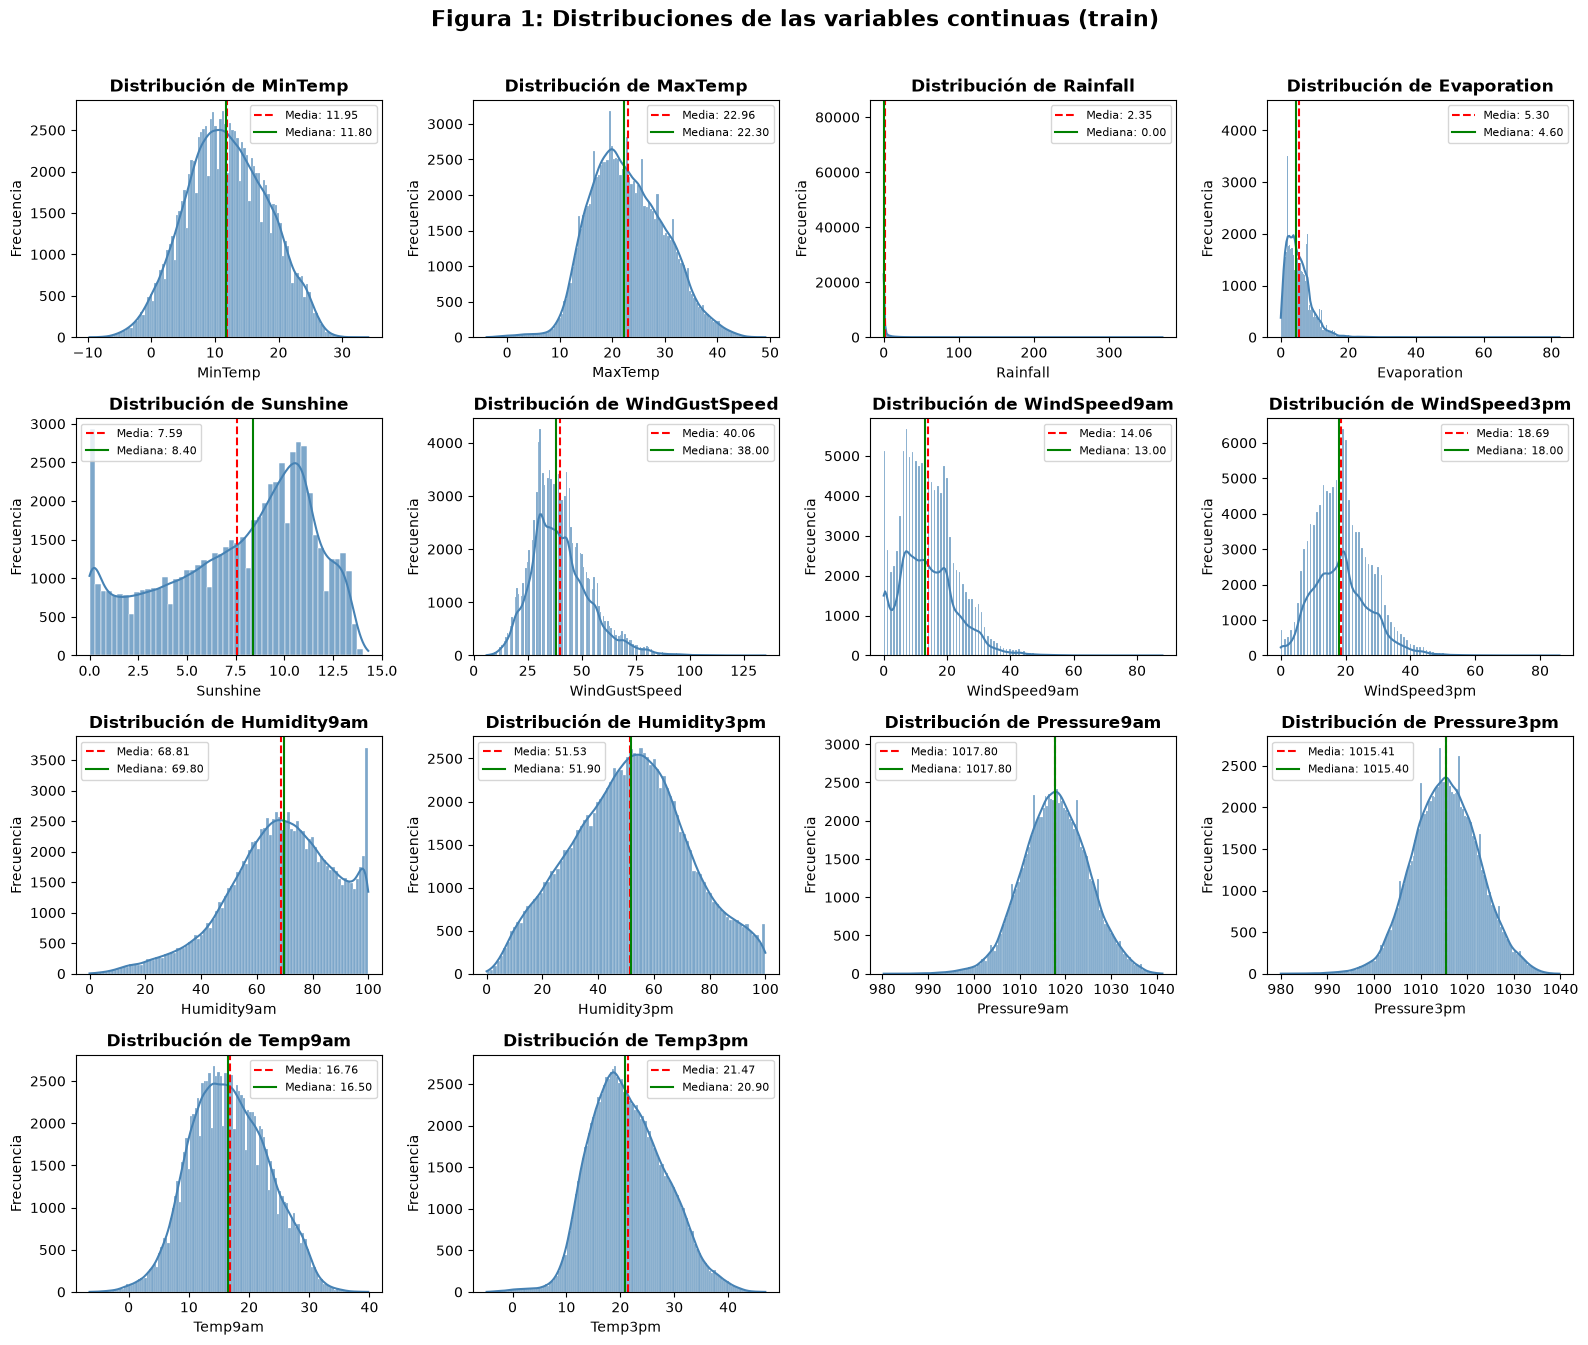

In [125]:
## Histogramas y estimación de densidad (KDE) de las variables continuas, con media y mediana

fig, axes = plt.subplots(5, 4, figsize=(16, 16))
axes = axes.flatten()

for i, col in enumerate(cols_continuas):
    ax = axes[i]
    sns.histplot(X_train[col], kde=True, ax=ax, color='steelblue', edgecolor='white', alpha=0.7)

    media = X_train[col].mean()
    mediana = X_train[col].median()
    ax.axvline(media, color='red', linestyle='--', linewidth=1.5, label=f'Media: {media:.2f}')
    ax.axvline(mediana, color='green', linestyle='-', linewidth=1.5, label=f'Mediana: {mediana:.2f}')

    ax.set_title(f'Distribución de {col}', fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')
    ax.legend(fontsize=8)

for j in range(len(cols_continuas), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Figura {N_FIG}: Distribuciones de las variables continuas (train)',
              fontsize=16, fontweight='bold', y=1.01)
N_FIG += 1
plt.tight_layout()
plt.show()

Los histogramas y las curvas KDE muestran distribuciones asimétricas, no concentradas de forma simétrica alrededor de la media. Rainfall presenta una marcada asimetría hacia la derecha: predominan los valores bajos y una cola larga se extiende hacia acumulados altos. Evaporation también muestra sesgo y una cola hacia valores elevados, de modo que media y mediana no describen por sí solas toda la forma de estas variables.

# 7. Boxplots para variables cuantitativas 

C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\3319289996.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(datos, vert=True, patch_artist=True,
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\3319289996.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(datos, vert=True, patch_artist=True,
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\3319289996.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[i].boxplot(datos, vert=True, patch_artist=True,
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\3319289996.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be r

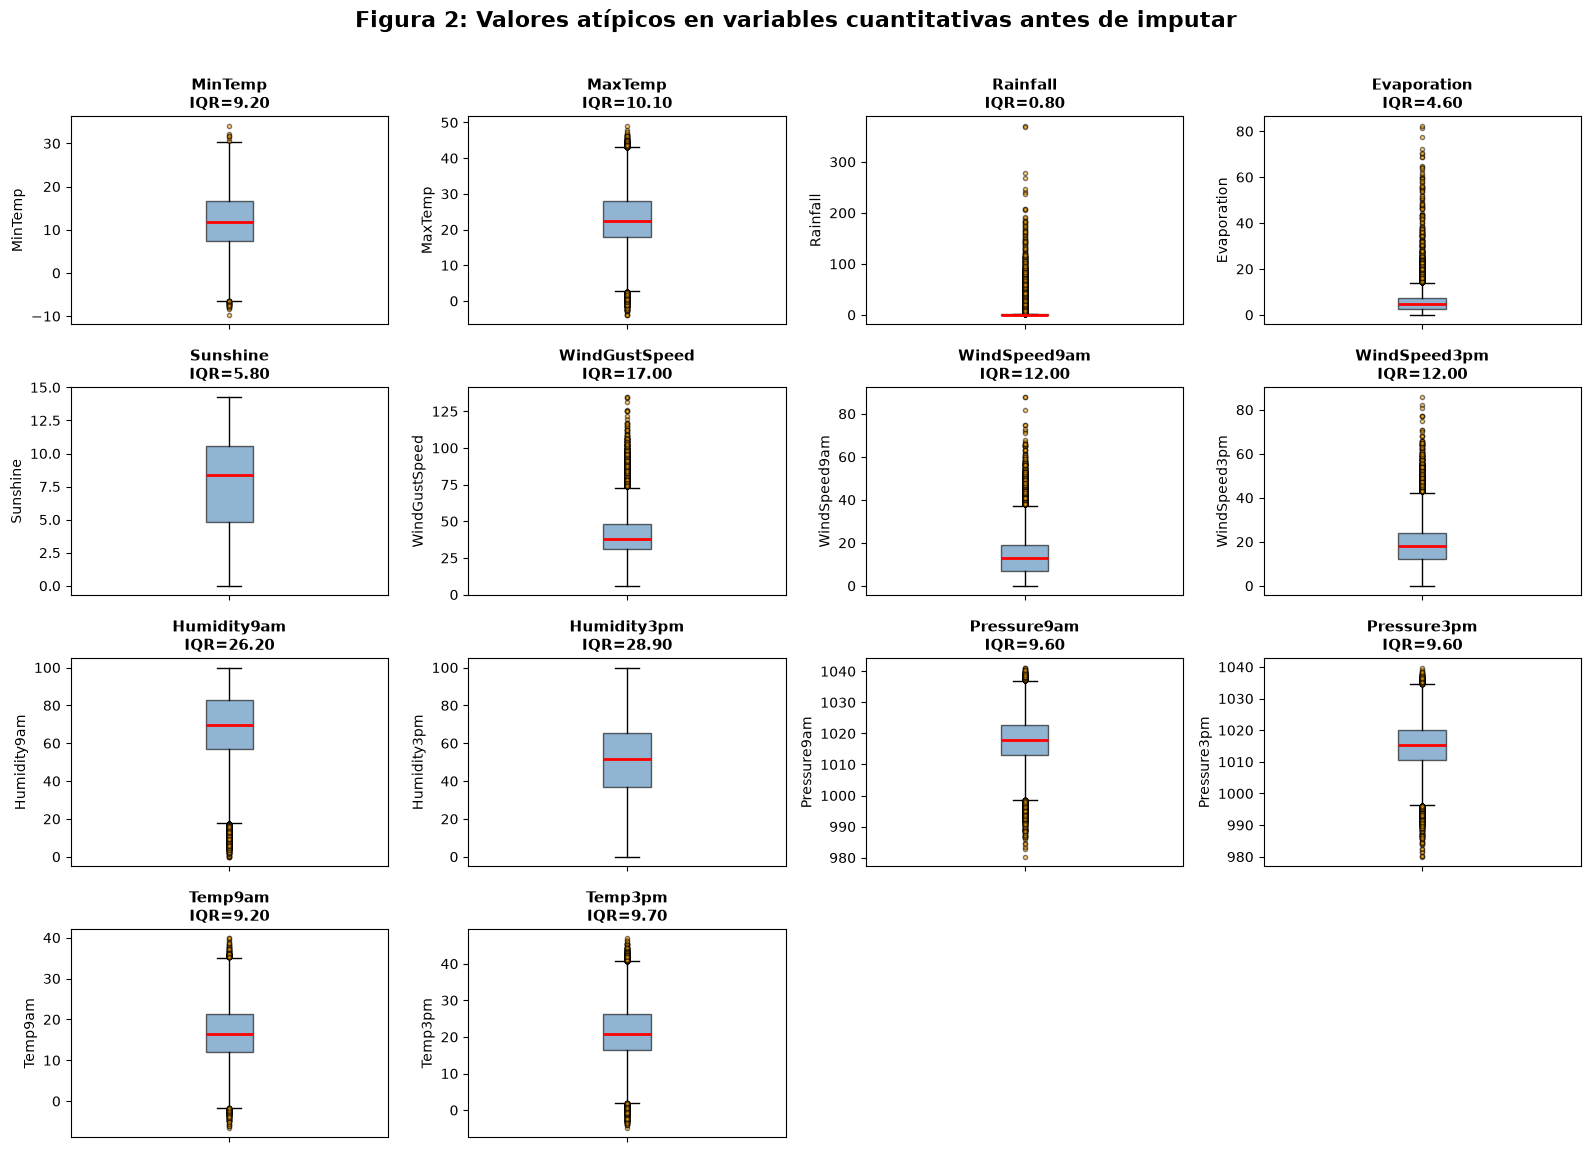

In [126]:
# Variables continuas

fig, axes = plt.subplots(5, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(cols_continuas):
    datos = X_train[col].dropna()          # los faltantes aún no se imputaron
    axes[i].boxplot(datos, vert=True, patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6),
                    medianprops=dict(color='red', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='orange', markersize=3, alpha=0.5))
    q1, q3 = datos.quantile(0.25), datos.quantile(0.75)
    axes[i].set_title(f'{col}\nIQR={q3 - q1:.2f}', fontweight='bold', fontsize=11)
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis='x', labelbottom=False)

for j in range(len(cols_continuas), len(axes)):
    axes[j].set_visible(False)

plt.suptitle(f'Figura {N_FIG}: Valores atípicos en variables cuantitativas antes de imputar',
            fontsize=16, fontweight='bold', y=1.01)
N_FIG += 1
plt.tight_layout()
plt.show()

Los diagramas de caja señalan observaciones fuera de los bigotes, en particular para Rainfall el cual observamos una gran cantidad de valores atípicos. Como muchas de las variables presentan outliers, este tipo de gráfico justifica la elección de utilizar un escalado robusto frente a estos atípicos.

# 8. Distribución de las variables discretas

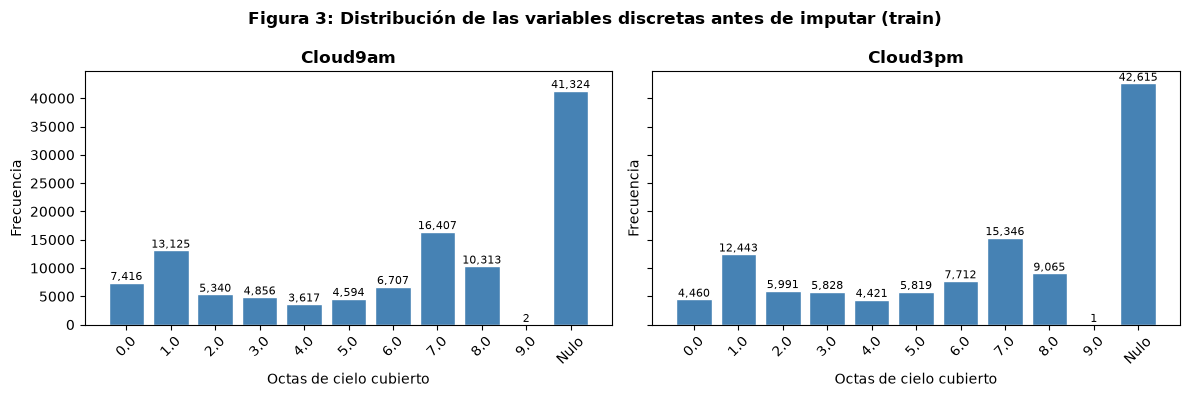

In [127]:
# Distribución de las variables discretas antes de imputar
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, columna in zip(axes, ["Cloud9am", "Cloud3pm"]):
    conteos = X_train[columna].value_counts(dropna=False).sort_index(na_position="last")
    etiquetas = ["Nulo" if pd.isna(valor) else str(valor) for valor in conteos.index]
    ax.bar(etiquetas, conteos.values, color="steelblue", edgecolor="white")
    ax.set_title(columna, fontweight="bold")
    ax.set_xlabel("Octas de cielo cubierto")
    ax.set_ylabel("Frecuencia")
    ax.tick_params(axis="x", rotation=45)
    for posicion, frecuencia in enumerate(conteos.values):
        ax.text(posicion, frecuencia, f"{frecuencia:,}", ha="center", va="bottom", fontsize=8)

fig.suptitle(f"Figura {N_FIG}: Distribución de las variables discretas antes de imputar (train)", fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

Cloud9am y Cloud3pm son variables discretas con frecuencias repartidas entre octas y una proporción elevada de faltantes: 36,34 % y 37,48 %, respectivamente. En ambas, el valor más frecuente es 7. El valor 9 aparece solo dos veces en Cloud9am y una vez en Cloud3pm; al ser inválido para esta escala, se excluyó en los pasos posteriores en lugar de tratarlo como una categoría ordinaria.

## 9. Distribución de las variables cualitativas

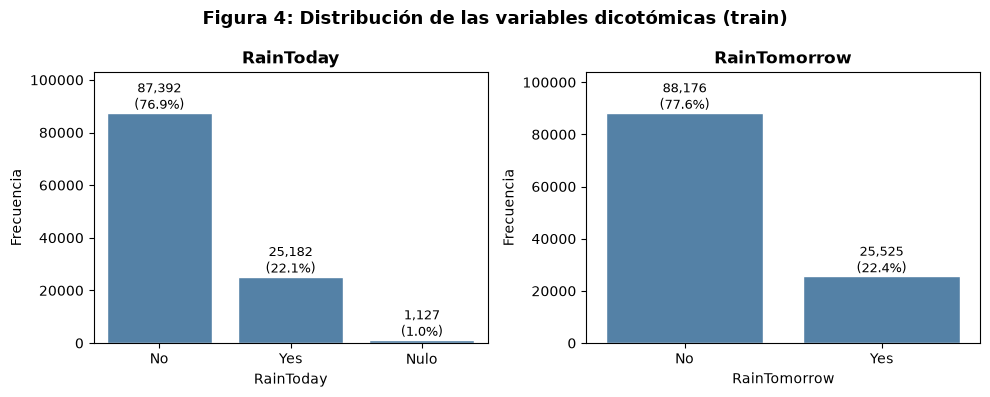

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (nombre, serie) in zip(axes, [("RainToday", X_train["RainToday"]),
                                      ("RainTomorrow", y_train)]):
    conteo = serie.value_counts(dropna=False)
    conteo.index = conteo.index.fillna("Nulo")
    sns.barplot(x=conteo.index, y=conteo.values, ax=ax, color="steelblue", edgecolor="white")
    for i, v in enumerate(conteo.values):
        ax.text(i, v, f"{v:,}\n({v / conteo.sum():.1%})", ha="center", va="bottom", fontsize=9)
    ax.set_title(nombre, fontweight="bold")
    ax.set_ylabel("Frecuencia")
    ax.set_ylim(0, conteo.max() * 1.18)

plt.suptitle(f"Figura {N_FIG}: Distribución de las variables dicotómicas (train)",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

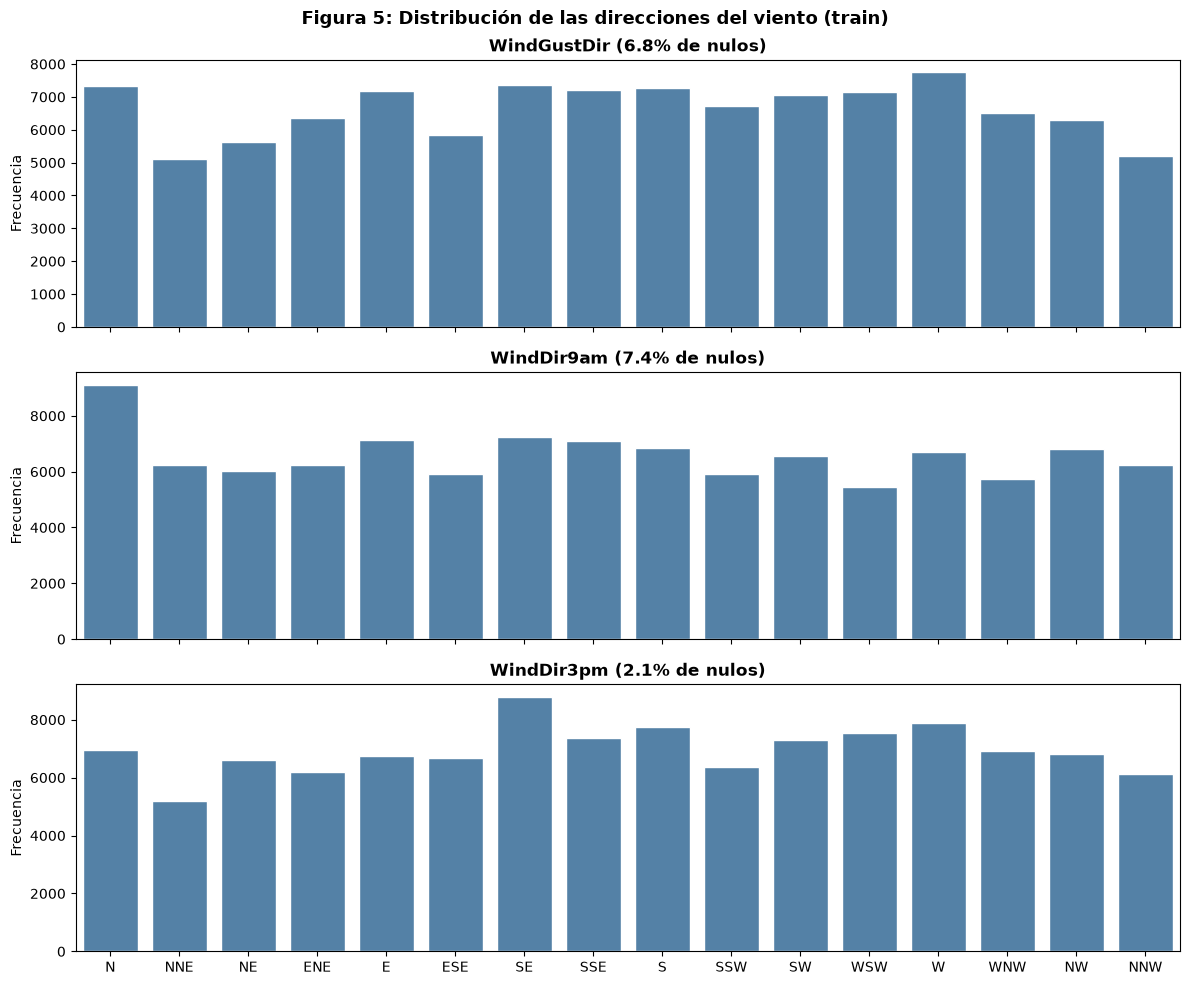

In [129]:
orden_viento = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
cols_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, col in zip(axes, cols_viento):
    sns.countplot(x=X_train[col], order=orden_viento, ax=ax, color="steelblue", edgecolor="white")
    pct_nulos = X_train[col].isna().mean() * 100
    ax.set_title(f"{col} ({pct_nulos:.1f}% de nulos)", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Frecuencia")

plt.suptitle(f"Figura {N_FIG}: Distribución de las direcciones del viento (train)",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

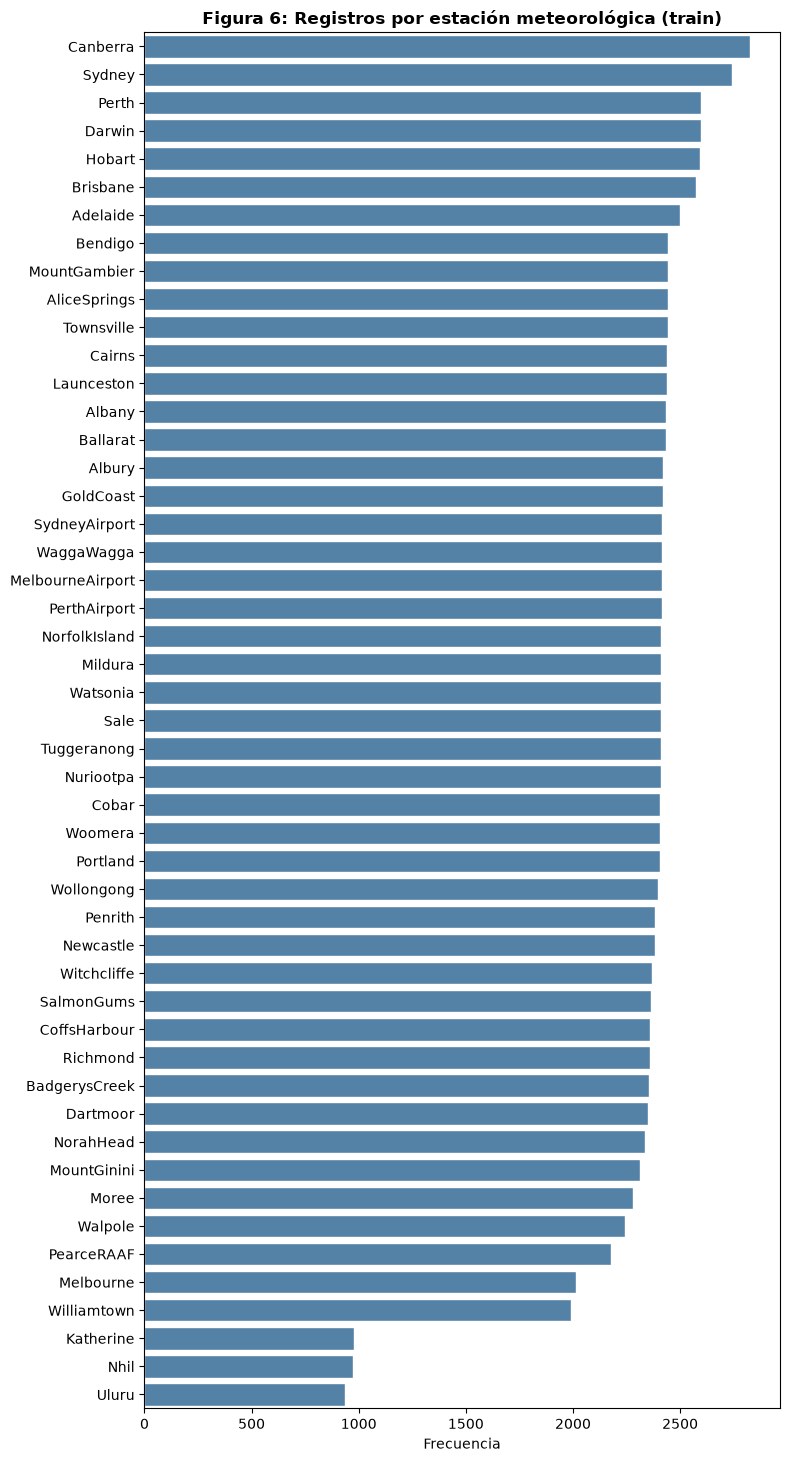

In [130]:
conteo_loc = X_train["Location"].value_counts()

fig, ax = plt.subplots(figsize=(8, 0.28 * len(conteo_loc) + 1))
sns.barplot(x=conteo_loc.values, y=conteo_loc.index, ax=ax, color="steelblue", edgecolor="white")
ax.set_title(f"Figura {N_FIG}: Registros por estación meteorológica (train)", fontweight="bold")
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
N_FIG += 1
plt.tight_layout()
plt.show()

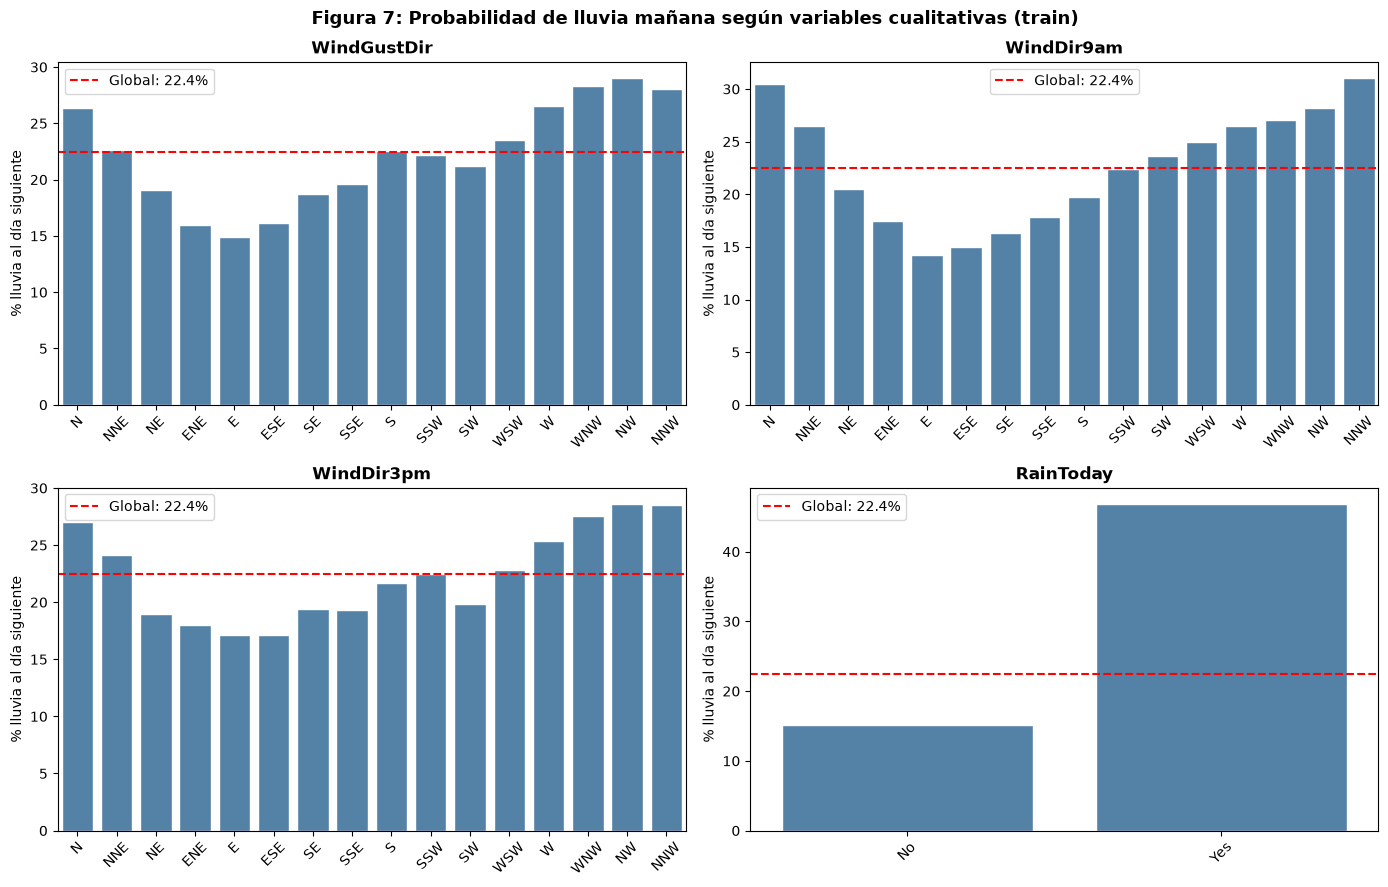

In [131]:
tasa_global = (y_train == "Yes").mean()
y_bin = (y_train == "Yes").astype(int)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, col in zip(axes, ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday"]):
    tasa = y_bin.groupby(X_train[col]).mean() * 100
    if col != "RainToday":
        tasa = tasa.reindex(orden_viento)
    sns.barplot(x=tasa.index, y=tasa.values, ax=ax, color="steelblue", edgecolor="white")
    ax.axhline(tasa_global * 100, color="red", linestyle="--", label=f"Global: {tasa_global:.1%}")
    ax.set_title(col, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% lluvia al día siguiente")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.suptitle(f"Figura {N_FIG}: Probabilidad de lluvia mañana según variables cualitativas (train)",
             fontsize=13, fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

En train, RainTomorrow presenta 77,55 % de casos No y 22,45 % Yes. Los gráficos también muestran una asociación descriptiva entre RainToday y la lluvia del día siguiente: la proporción de Yes es aproximadamente 46,9 % cuando RainToday es Yes y 15,1 % cuando es No. Las tasas varían asimismo entre direcciones del viento y localidades, pero estas diferencias observacionales no prueban causalidad ni deben interpretarse como efectos aislados de cada categoría.

# 10. Matriz de correlación de Spearman y gráficos de dispersión

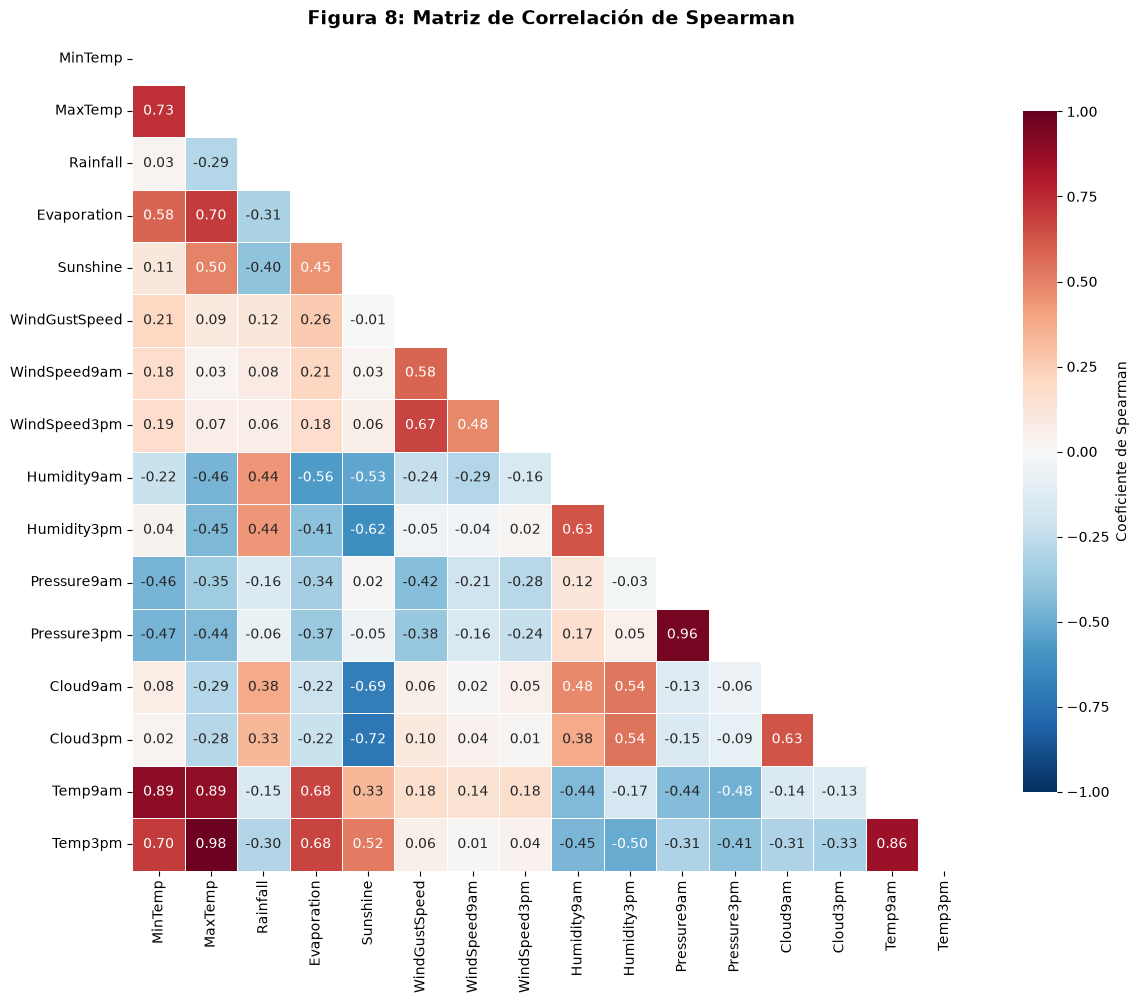

In [132]:
# Matriz de correlación de Spearman (solo variables numéricas)
corr_spearman = X_train.corr(method='spearman', numeric_only=True)

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_spearman, mask=mask, annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8, 'label': 'Coeficiente de Spearman'})
ax.set_title(f'Figura {N_FIG}: Matriz de Correlación de Spearman', fontsize=14, fontweight='bold')
N_FIG += 1
plt.tight_layout()
plt.show()

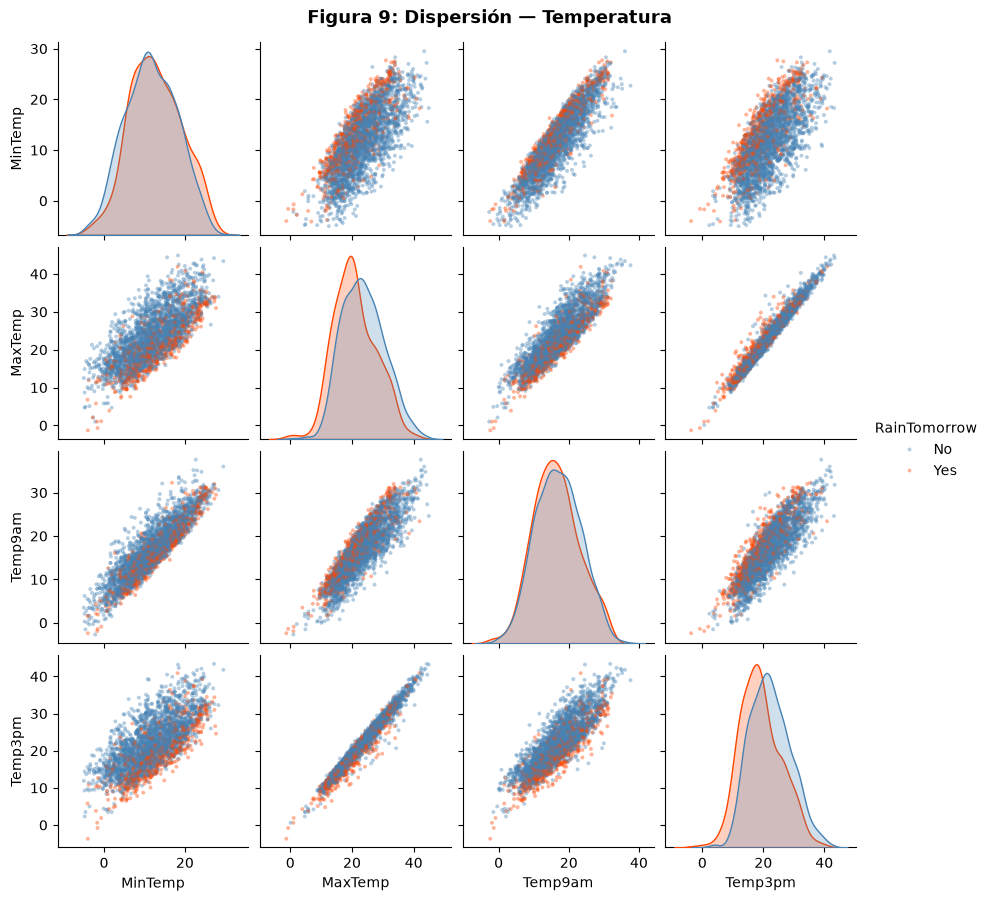

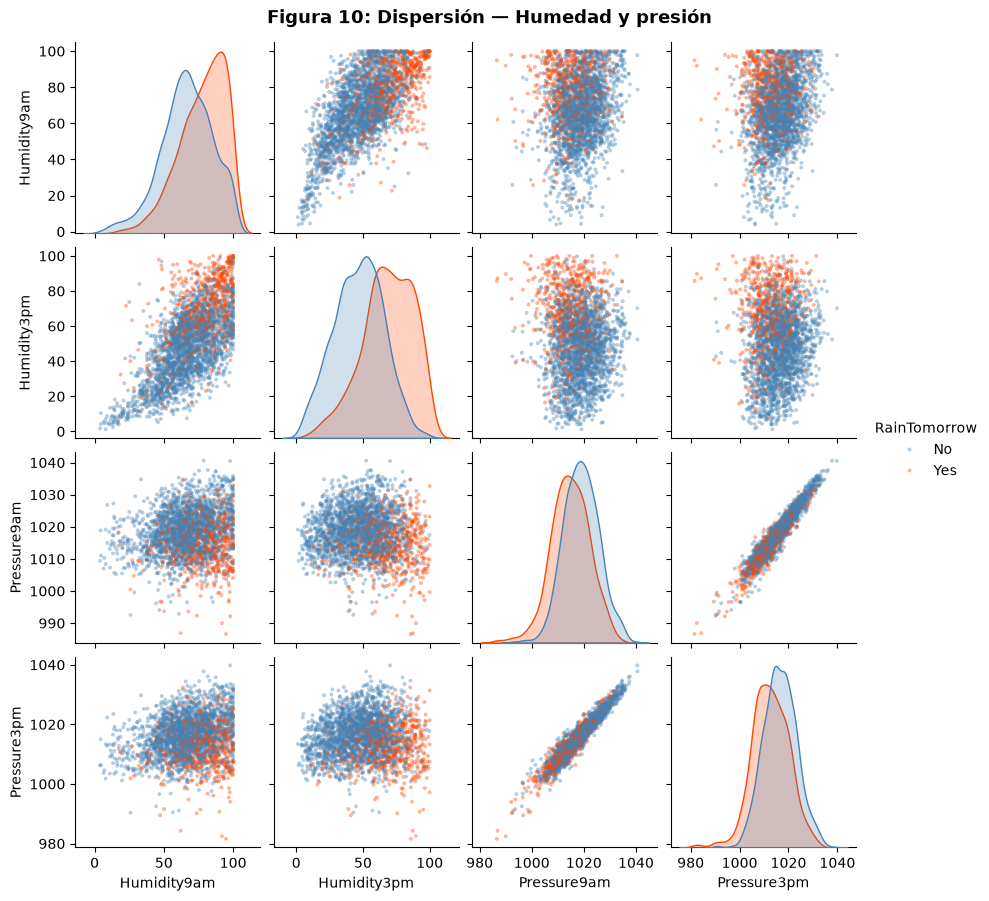

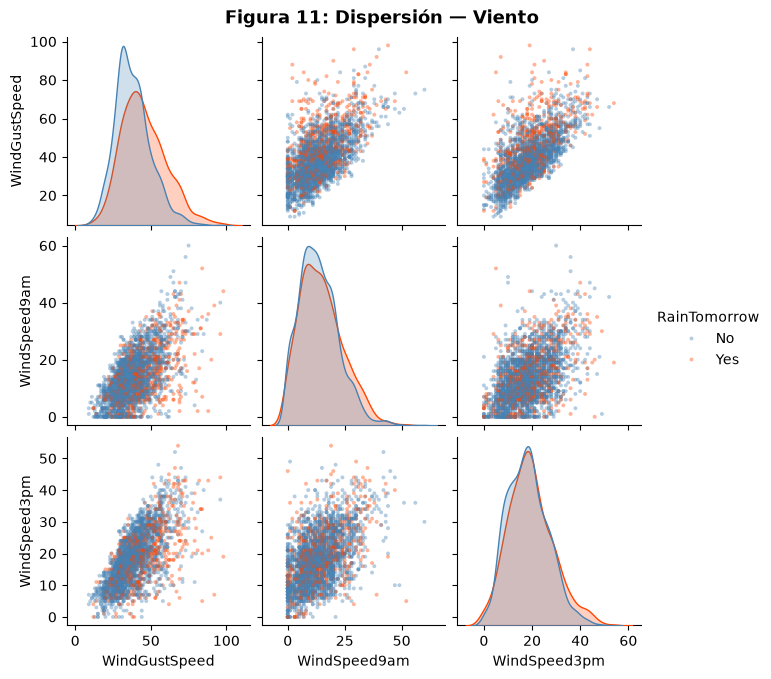

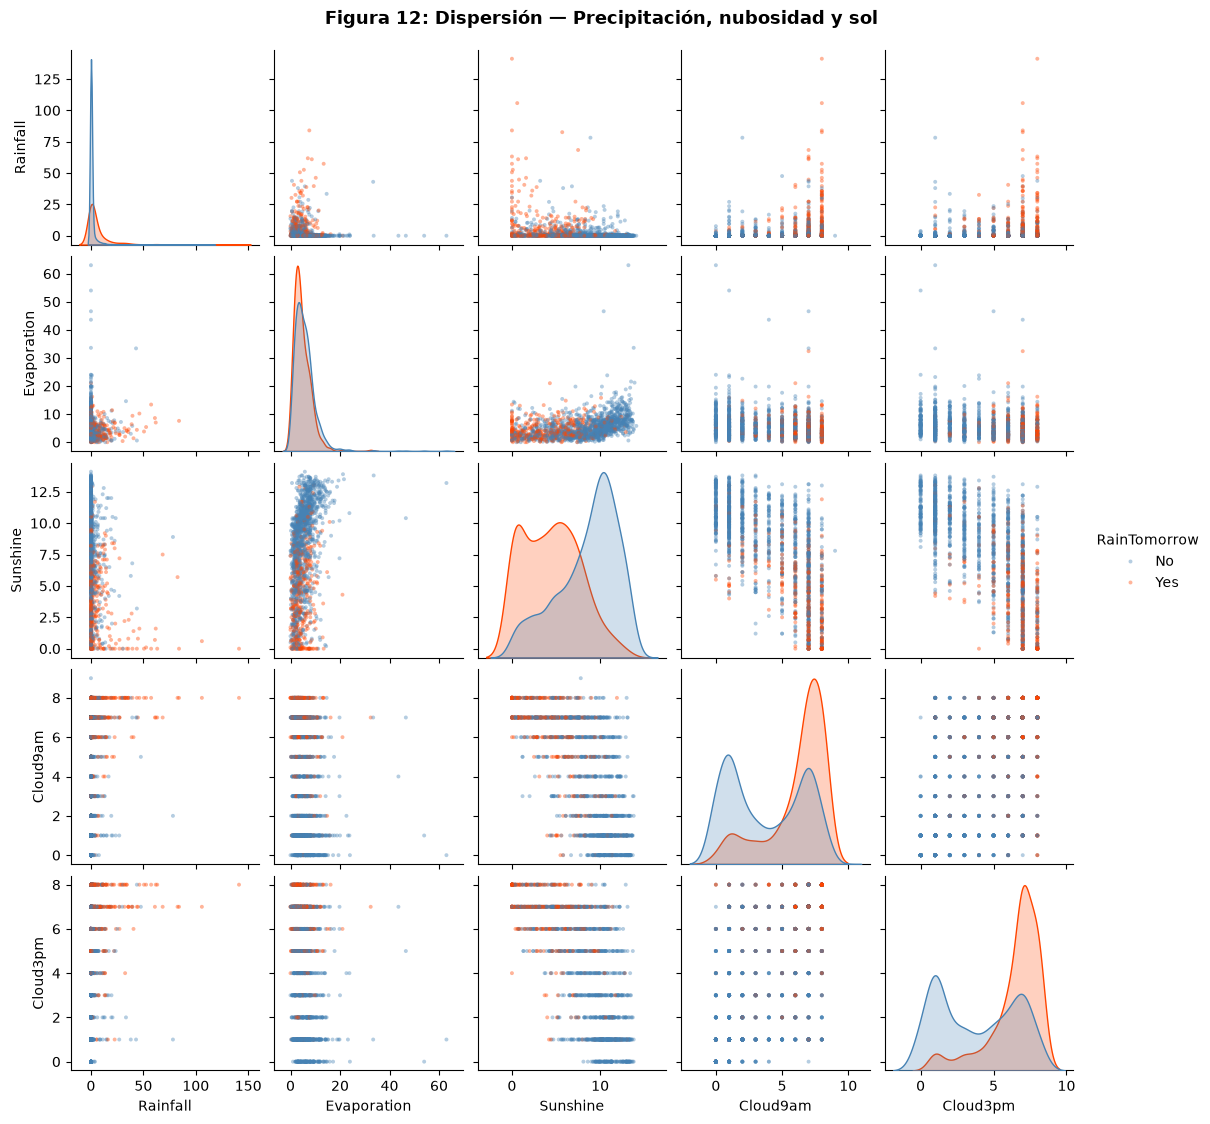

In [133]:
# Muestra aleatoria de train para que el gráfico sea liviano y legible
N_MUESTRA = 3000

datos_scatter = X_train[cols_numericas].copy()
datos_scatter["RainTomorrow"] = y_train          # alineado por índice
muestra = datos_scatter.sample(N_MUESTRA, random_state=RANDOM_STATE)

grupos = {
    "Temperatura": ["MinTemp", "MaxTemp", "Temp9am", "Temp3pm"],
    "Humedad y presión": ["Humidity9am", "Humidity3pm", "Pressure9am", "Pressure3pm"],
    "Viento": ["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"],
    "Precipitación, nubosidad y sol": ["Rainfall", "Evaporation", "Sunshine", "Cloud9am", "Cloud3pm"],
}

for nombre, variables in grupos.items():
    g = sns.pairplot(
        muestra, vars=variables, hue="RainTomorrow", hue_order=["No", "Yes"],
        palette={"No": "steelblue", "Yes": "orangered"},
        diag_kind="kde", plot_kws=dict(s=8, alpha=0.4, edgecolor="none"),
        diag_kws=dict(common_norm=False, fill=True), height=2.2,
    )
    g.figure.suptitle(f"Figura {N_FIG}: Dispersión — {nombre}", fontsize=13, fontweight="bold", y=1.02)
    N_FIG += 1
    plt.show()

In [134]:
X_train['Cloud9am'].value_counts().sort_index()

Cloud9am
0.0     7416
1.0    13125
2.0     5340
3.0     4856
4.0     3617
5.0     4594
6.0     6707
7.0    16407
8.0    10313
9.0        2
Name: count, dtype: int64

La matriz de Spearman destaca asociaciones monotónicas fuertes entre MaxTemp y Temp3pm (0,979), Pressure9am y Pressure3pm (0,958), y MinTemp y Temp9am (0,892); Sunshine y Cloud3pm presentan una asociación inversa marcada (-0,719). Esto señala información compartida entre predictores, no causalidad. En este trabajo se eliminan Temp3pm, Temp9am y Pressure9am por su alta correlación con MaxTemp, MinTemp y Pressure3pm, respectivamente. Esta reducción evita conservar predictores redundantes; su impacto final deberá evaluarse con validación temporal usando solo train y dejando test para la evaluación final.

In [135]:
# Eliminamos los predictores redundantes identificados en la matriz de Spearman.
variables_colineales = ["Temp3pm", "Temp9am", "Pressure9am"]
for conjunto in (train, test, X_train, X_test):
    conjunto.drop(columns=variables_colineales, inplace=True)

cols_numericas = [col for col in cols_numericas if col not in variables_colineales]
cols_continuas = [col for col in cols_continuas if col not in variables_colineales]

assert all(col not in X_train.columns for col in variables_colineales)
assert all(col not in X_test.columns for col in variables_colineales)
print(f"Predictores eliminados: {variables_colineales}")
print(f"Columnas restantes: {X_train.shape[1]} en train y {X_test.shape[1]} en test.")

Predictores eliminados: ['Temp3pm', 'Temp9am', 'Pressure9am']
Columnas restantes: 19 en train y 19 en test.


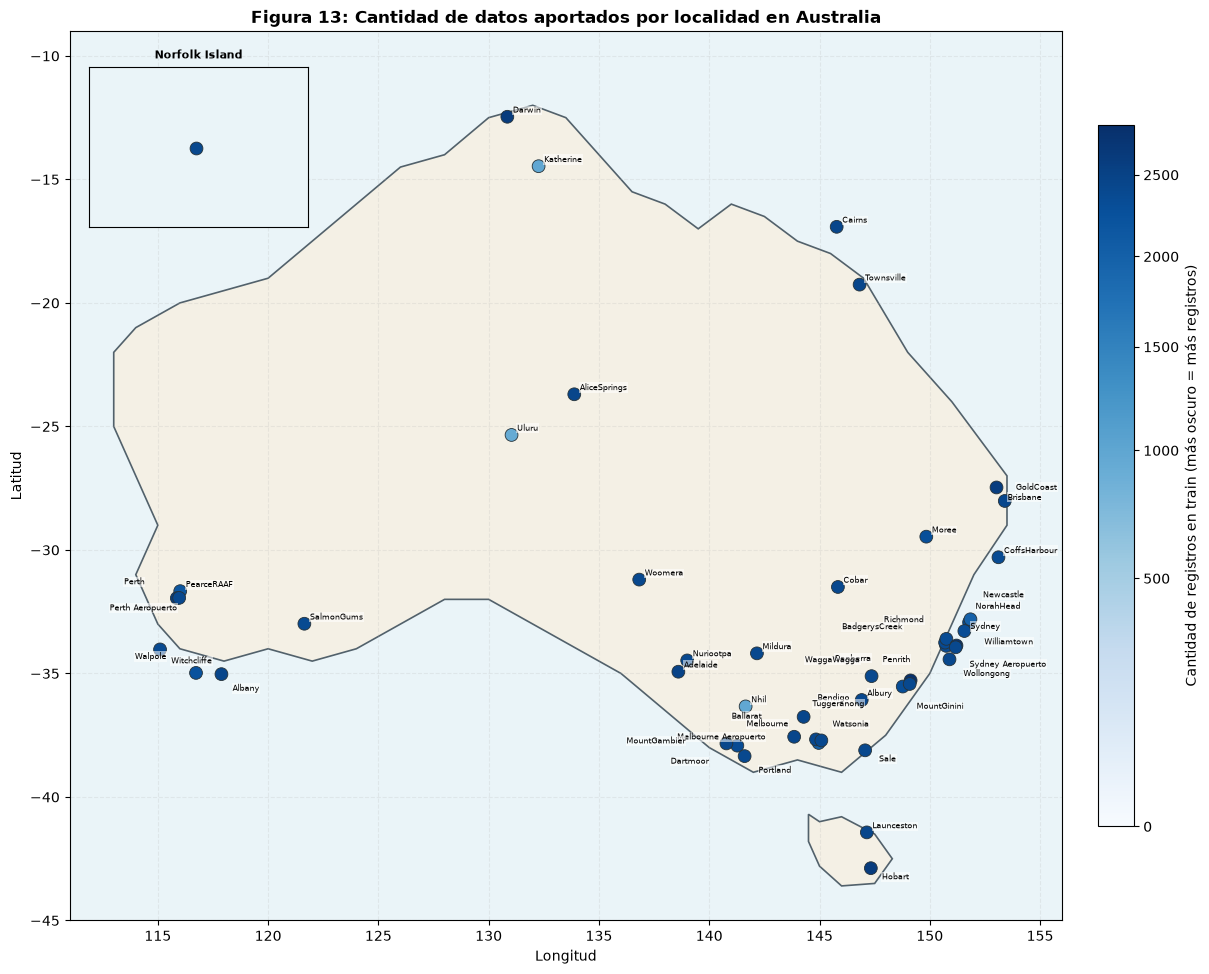

In [136]:
# Mapa de Australia: cada estaci?n se colorea seg?n su cantidad de registros en train.
from matplotlib.colors import PowerNorm

coordenadas_localidades = {
    "Adelaide": (-34.9285, 138.6007),
    "Albany": (-35.0275, 117.8840),
    "Albury": (-36.0737, 146.9135),
    "AliceSprings": (-23.6980, 133.8807),
    "BadgerysCreek": (-33.8828, 150.7445),
    "Ballarat": (-37.5622, 143.8503),
    "Bendigo": (-36.7570, 144.2794),
    "Brisbane": (-27.4698, 153.0251),
    "Cairns": (-16.9186, 145.7781),
    "Canberra": (-35.2809, 149.1300),
    "Cobar": (-31.4983, 145.8344),
    "CoffsHarbour": (-30.2963, 153.1135),
    "Dartmoor": (-37.9222, 141.2743),
    "Darwin": (-12.4634, 130.8456),
    "GoldCoast": (-28.0167, 153.4000),
    "Hobart": (-42.8821, 147.3272),
    "Katherine": (-14.4652, 132.2635),
    "Launceston": (-41.4332, 147.1448),
    "Melbourne": (-37.8136, 144.9631),
    "MelbourneAirport": (-37.6690, 144.8410),
    "Mildura": (-34.1855, 142.1625),
    "Moree": (-29.4617, 149.8416),
    "MountGambier": (-37.8318, 140.7792),
    "MountGinini": (-35.5294, 148.7728),
    "Newcastle": (-32.9283, 151.7817),
    "Nhil": (-36.3333, 141.6500),
    "NorahHead": (-33.2817, 151.5675),
    "NorfolkIsland": (-29.0408, 167.9547),
    "Nuriootpa": (-34.4721, 139.0010),
    "PearceRAAF": (-31.6675, 116.0150),
    "Penrith": (-33.7511, 150.6942),
    "Perth": (-31.9505, 115.8605),
    "PerthAirport": (-31.9403, 115.9669),
    "Portland": (-38.3460, 141.6042),
    "Richmond": (-33.5995, 150.7510),
    "Sale": (-38.1109, 147.0680),
    "SalmonGums": (-32.9867, 121.6436),
    "Sydney": (-33.8688, 151.2093),
    "SydneyAirport": (-33.9399, 151.1753),
    "Townsville": (-19.2589, 146.8169),
    "Tuggeranong": (-35.4244, 149.0888),
    "Uluru": (-25.3444, 131.0369),
    "WaggaWagga": (-35.1082, 147.3598),
    "Walpole": (-34.9774, 116.7310),
    "Watsonia": (-37.7104, 145.0836),
    "Williamtown": (-32.8069, 151.8428),
    "Witchcliffe": (-34.0267, 115.1000),
    "Wollongong": (-34.4278, 150.8931),
    "Woomera": (-31.1999, 136.8259),
}


# Contornos simplificados para mostrar Australia continental y Tasmania sin dependencias geogr?ficas externas.
contorno_australia = np.array([
    [113.0, -22.0], [114.0, -21.0], [116.0, -20.0], [118.0, -19.5],
    [120.0, -19.0], [122.0, -17.5], [124.0, -16.0], [126.0, -14.5],
    [128.0, -14.0], [130.0, -12.5], [132.0, -12.0], [133.5, -12.5],
    [135.0, -14.0], [136.5, -15.5], [138.0, -16.0], [139.5, -17.0],
    [141.0, -16.0], [142.5, -16.5], [144.0, -17.5], [145.5, -18.0],
    [147.0, -19.0], [149.0, -22.0], [151.0, -24.0], [153.5, -27.0],
    [153.5, -29.0], [152.0, -31.0], [151.0, -33.0], [150.0, -35.0],
    [148.0, -37.5], [146.0, -39.0], [144.0, -38.5], [142.0, -39.0],
    [140.0, -38.0], [138.0, -36.5], [136.0, -35.0], [134.0, -34.0],
    [132.0, -33.0], [130.0, -32.0], [128.0, -32.0], [126.0, -33.0],
    [124.0, -34.0], [122.0, -34.5], [120.0, -34.0], [118.0, -34.5],
    [116.0, -34.0], [115.0, -33.0], [114.0, -31.0], [115.0, -29.0],
    [114.0, -27.0], [113.0, -25.0], [113.0, -22.0],
])
contorno_tasmania = np.array([
    [144.5, -40.7], [145.0, -41.0], [146.0, -40.8], [147.5, -41.5],
    [148.3, -42.5], [147.5, -43.5], [146.0, -43.6], [145.0, -42.8],
    [144.5, -41.8], [144.5, -40.7],
])

conteo_localidades_mapa = X_train["Location"].value_counts()
localidades_mapa = sorted(conteo_localidades_mapa.index)
localidades_sin_coordenadas = sorted(set(localidades_mapa) - set(coordenadas_localidades))
if localidades_sin_coordenadas:
    raise ValueError(f"Faltan coordenadas para localidades de train: {localidades_sin_coordenadas}")

longitudes_mapa = np.array([coordenadas_localidades[localidad][1] for localidad in localidades_mapa])
latitudes_mapa = np.array([coordenadas_localidades[localidad][0] for localidad in localidades_mapa])
registros_mapa = conteo_localidades_mapa.loc[localidades_mapa].to_numpy()

fig, ax = plt.subplots(figsize=(13, 10))
ax.set_facecolor("#eaf4f8")
for contorno in (contorno_australia, contorno_tasmania):
    ax.fill(contorno[:, 0], contorno[:, 1], facecolor="#f4f0e5", edgecolor="#52616b", linewidth=1.2, zorder=1)

norma_color = PowerNorm(gamma=0.6, vmin=0, vmax=registros_mapa.max())
mascara_continente = np.array([localidad != "NorfolkIsland" for localidad in localidades_mapa])
if not mascara_continente.any():
    raise ValueError("No hay localidades continentales para representar en el mapa.")
puntos = ax.scatter(
    longitudes_mapa[mascara_continente], latitudes_mapa[mascara_continente],
    c=registros_mapa[mascara_continente], cmap="Blues", norm=norma_color,
    s=85, edgecolors="#263238", linewidths=0.6, zorder=3,
)

# Desplazamientos para que se lean mejor las etiquetas de localidades cercanas.
desplazamientos_etiquetas = {
    "Sydney": (10, 12), "SydneyAirport": (10, -14), "BadgerysCreek": (-75, 12),
    "Penrith": (-45, -14), "Richmond": (-45, 12), "Wollongong": (10, -12),
    "NorahHead": (8, 16), "Newcastle": (10, 18), "Williamtown": (10, -18),
    "Canberra": (-55, 14), "Tuggeranong": (-70, -16), "MountGinini": (10, -16),
    "WaggaWagga": (-48, 10), "Melbourne": (-52, 12), "MelbourneAirport": (-100, 0),
    "Watsonia": (8, 10), "Ballarat": (-45, 13), "Bendigo": (10, 12),
    "MountGambier": (-72, 0), "Portland": (10, -12), "Dartmoor": (-48, -13),
    "Sale": (10, -8), "Perth": (-38, 10), "PerthAirport": (-50, -9),
    "Albany": (8, -12), "Walpole": (-44, 10), "Witchcliffe": (8, -10),
    "GoldCoast": (8, 8), "Brisbane": (8, -9), "Hobart": (8, -8),
}
for localidad, longitud, latitud in zip(localidades_mapa, longitudes_mapa, latitudes_mapa):
    if localidad != "NorfolkIsland":
        desplazamiento = desplazamientos_etiquetas.get(localidad, (4, 3))
        ax.annotate(
            localidad.replace("Airport", " Aeropuerto"), (longitud, latitud),
            xytext=desplazamiento, textcoords="offset points", fontsize=5.5,
            bbox={"facecolor": "white", "alpha": 0.55, "edgecolor": "none", "pad": 0.5},
            zorder=4,
        )

barra_color = fig.colorbar(puntos, ax=ax, shrink=0.75, pad=0.03)
barra_color.set_label("Cantidad de registros en train (más oscuro = más registros)")
ax.set_title(f"Figura {N_FIG}: Cantidad de datos aportados por localidad en Australia", fontweight="bold")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_xlim(111, 156)
ax.set_ylim(-45, -9)
ax.set_aspect(1.12)
ax.grid(alpha=0.2, linestyle="--")

# Norfolk Island queda fuera de la escala continental; se muestra en un recuadro.
if "NorfolkIsland" in conteo_localidades_mapa.index:
    ax_inset = ax.inset_axes([0.02, 0.78, 0.22, 0.18])
    ax_inset.set_facecolor("#eaf4f8")
    ax_inset.scatter(
        [coordenadas_localidades["NorfolkIsland"][1]],
        [coordenadas_localidades["NorfolkIsland"][0]],
        c=[conteo_localidades_mapa["NorfolkIsland"]], cmap="Blues", norm=norma_color,
        s=85, edgecolors="#263238", linewidths=0.6,
    )
    ax_inset.set_xlim(166, 170)
    ax_inset.set_ylim(-31, -27)
    ax_inset.set_title("Norfolk Island", fontsize=8, fontweight="bold")
    ax_inset.set_xticks([])
    ax_inset.set_yticks([])
    ax_inset.grid(alpha=0.2)

N_FIG += 1
plt.tight_layout()
plt.show()


## 11. Imputación espacial por KNN 
Para cada valor faltante buscamos las 5 estaciones geográficamente más cercanas con una observación disponible de esa variable en la misma fecha. Usamos la mediana para variables numéricas y la moda para variables categóricas. La validación oculta el 10% de los valores observados de train. En test, la imputación usa únicamente predictores observados de otras estaciones de esa misma fecha; es una evaluación transductiva, válida si al predecir se dispone de las observaciones del resto de las estaciones para ese día. Nunca se utilizan `RainTomorrow` ni fechas futuras como donantes.

,Variable,Métrica,Valores ocultados,Casos evaluables,Cobertura (%),Resultado
0,MinTemp,MAE,11323,11311,99.894,2.806
1,MaxTemp,MAE,11348,11333,99.868,2.749
2,Rainfall,MAE,11257,11249,99.929,2.098
3,Evaporation,MAE,6936,6915,99.697,1.905
4,Sunshine,MAE,6518,6502,99.755,2.350
5,WindGustDir,Exactitud,10597,10576,99.802,0.183
6,WindGustSpeed,MAE,10603,10583,99.811,8.628
7,WindDir9am,Exactitud,10531,10511,99.810,0.187
8,WindDir3pm,Exactitud,11126,11118,99.928,0.198
9,WindSpeed9am,MAE,11250,11238,99.893,6.904


,Conjunto,Variable,Nulos antes,Imputados,Nulos después
0,Train,MinTemp,468,468,0
1,Train,MaxTemp,223,223,0
2,Train,Rainfall,1127,1127,0
3,Train,Evaporation,44334,44334,0
4,Train,Sunshine,48513,48513,0
5,Train,WindGustDir,7731,7727,4
6,Train,WindGustSpeed,7671,7669,2
7,Train,WindDir9am,8385,8383,2
8,Train,WindDir3pm,2436,2436,0
9,Train,WindSpeed9am,1203,1203,0


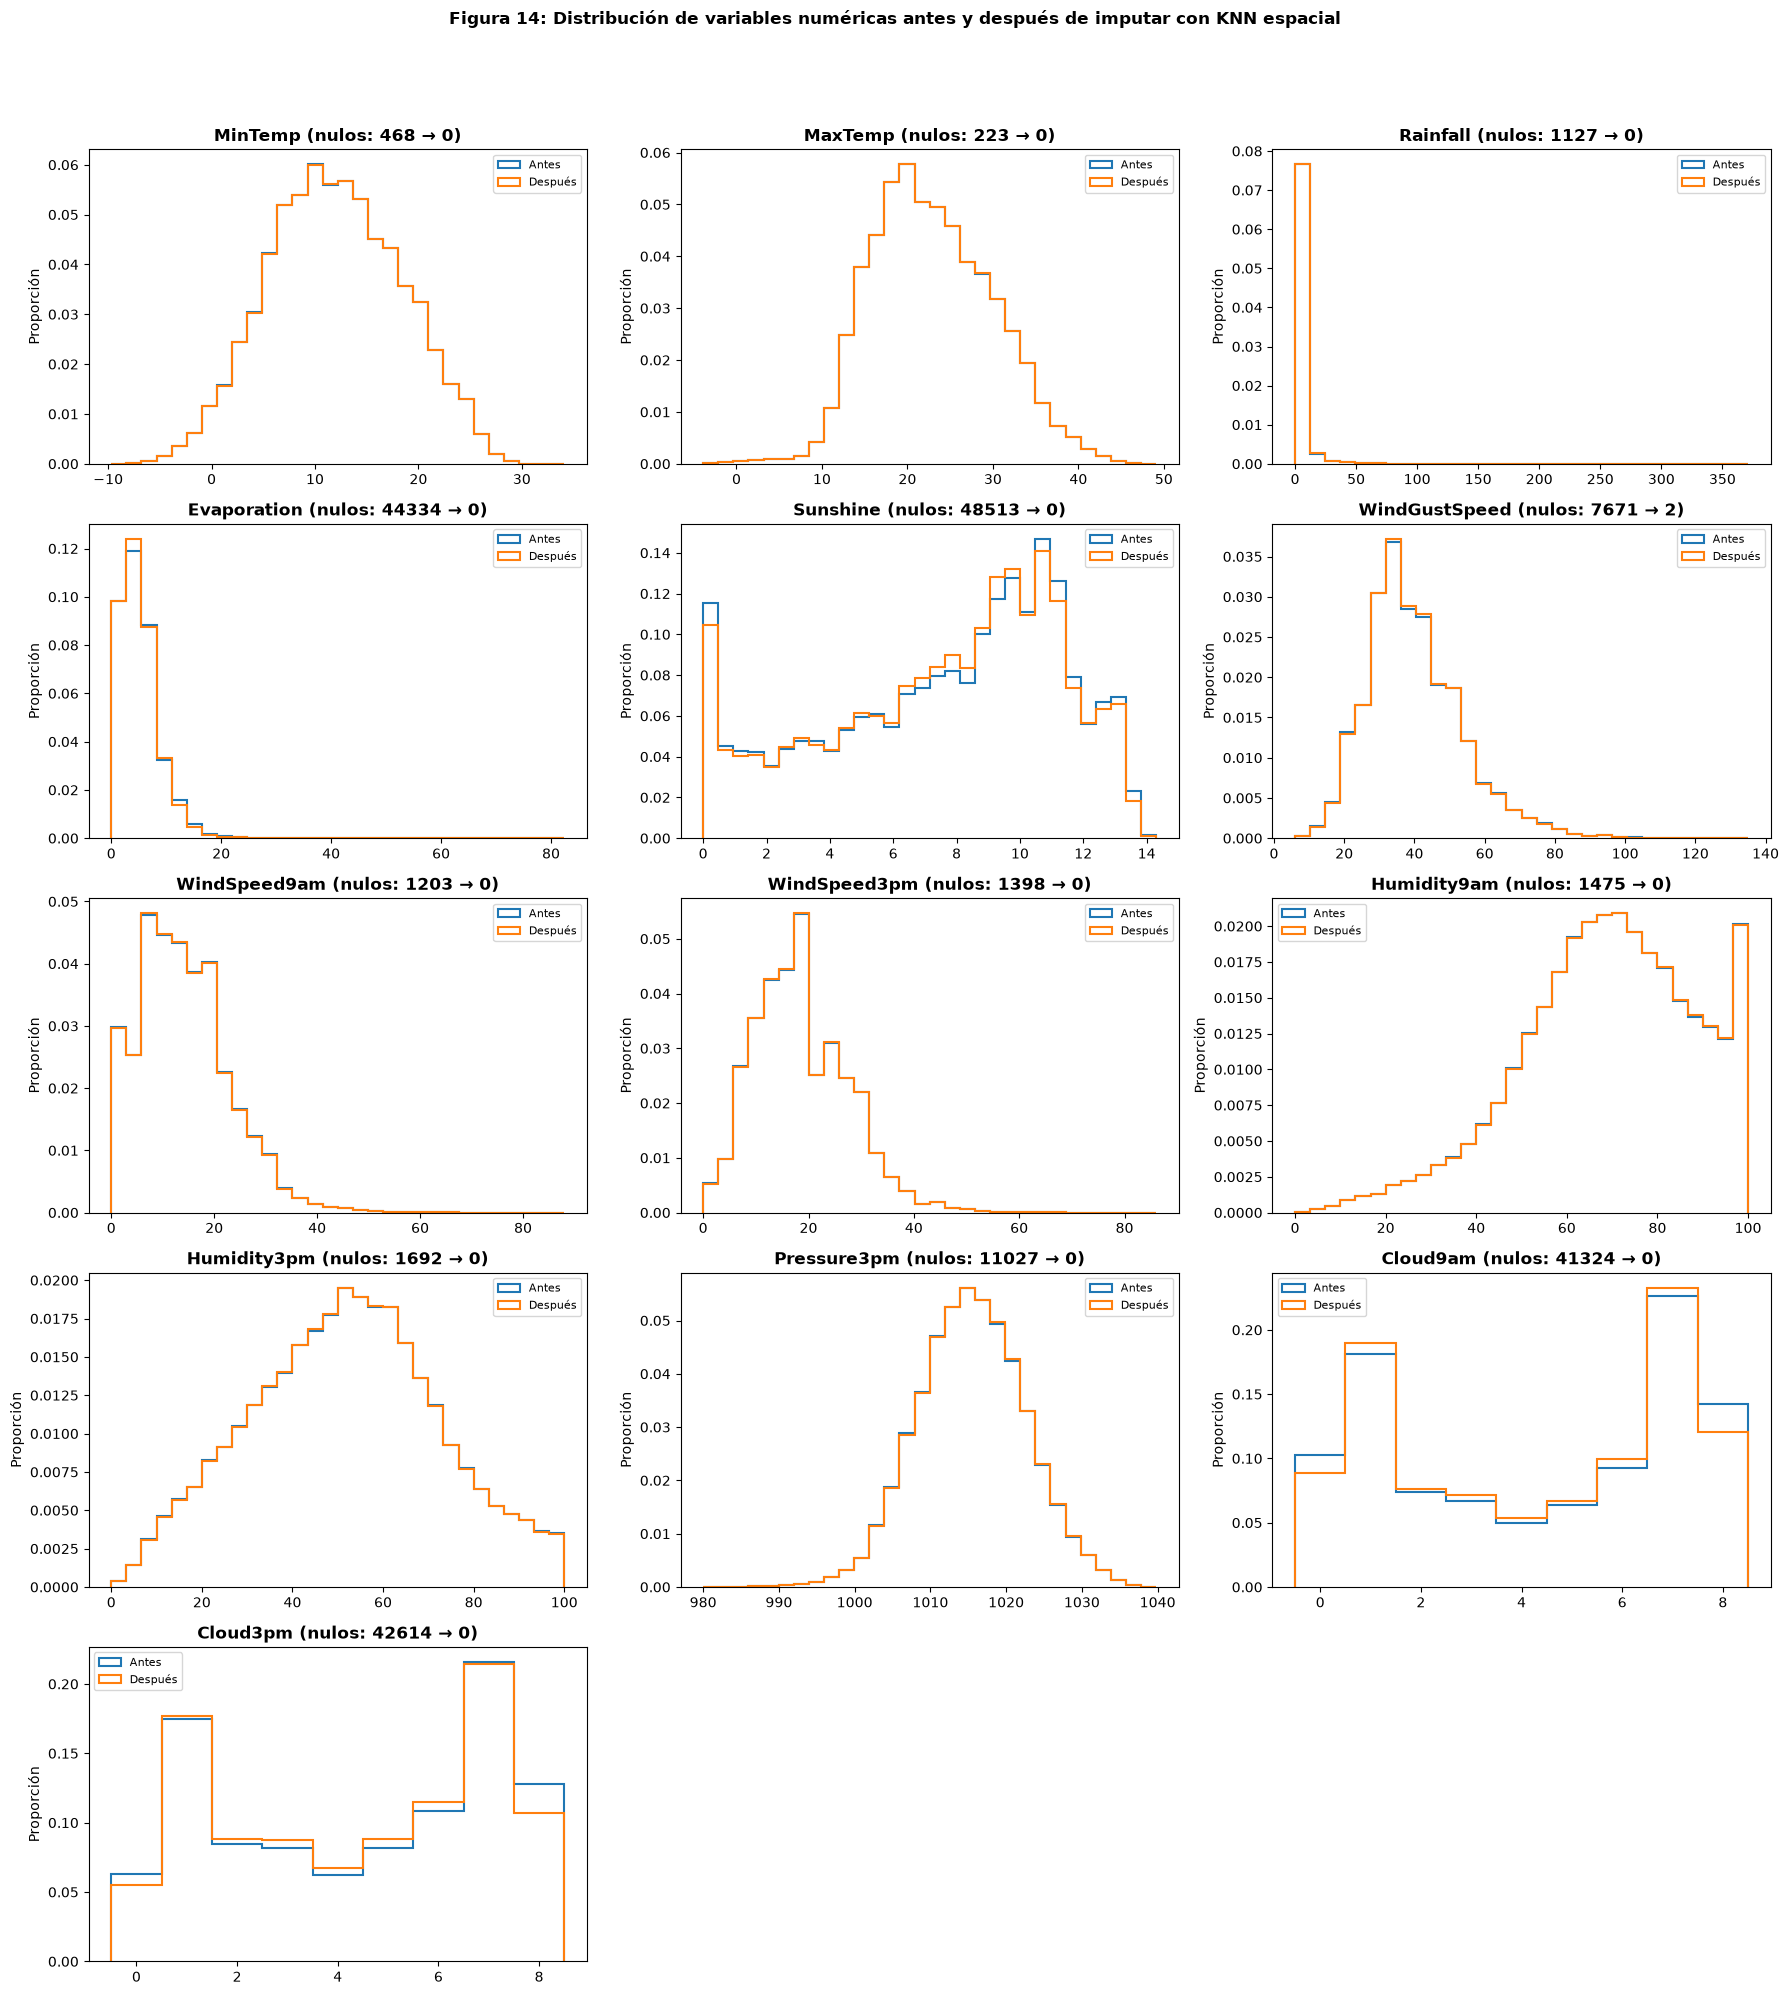

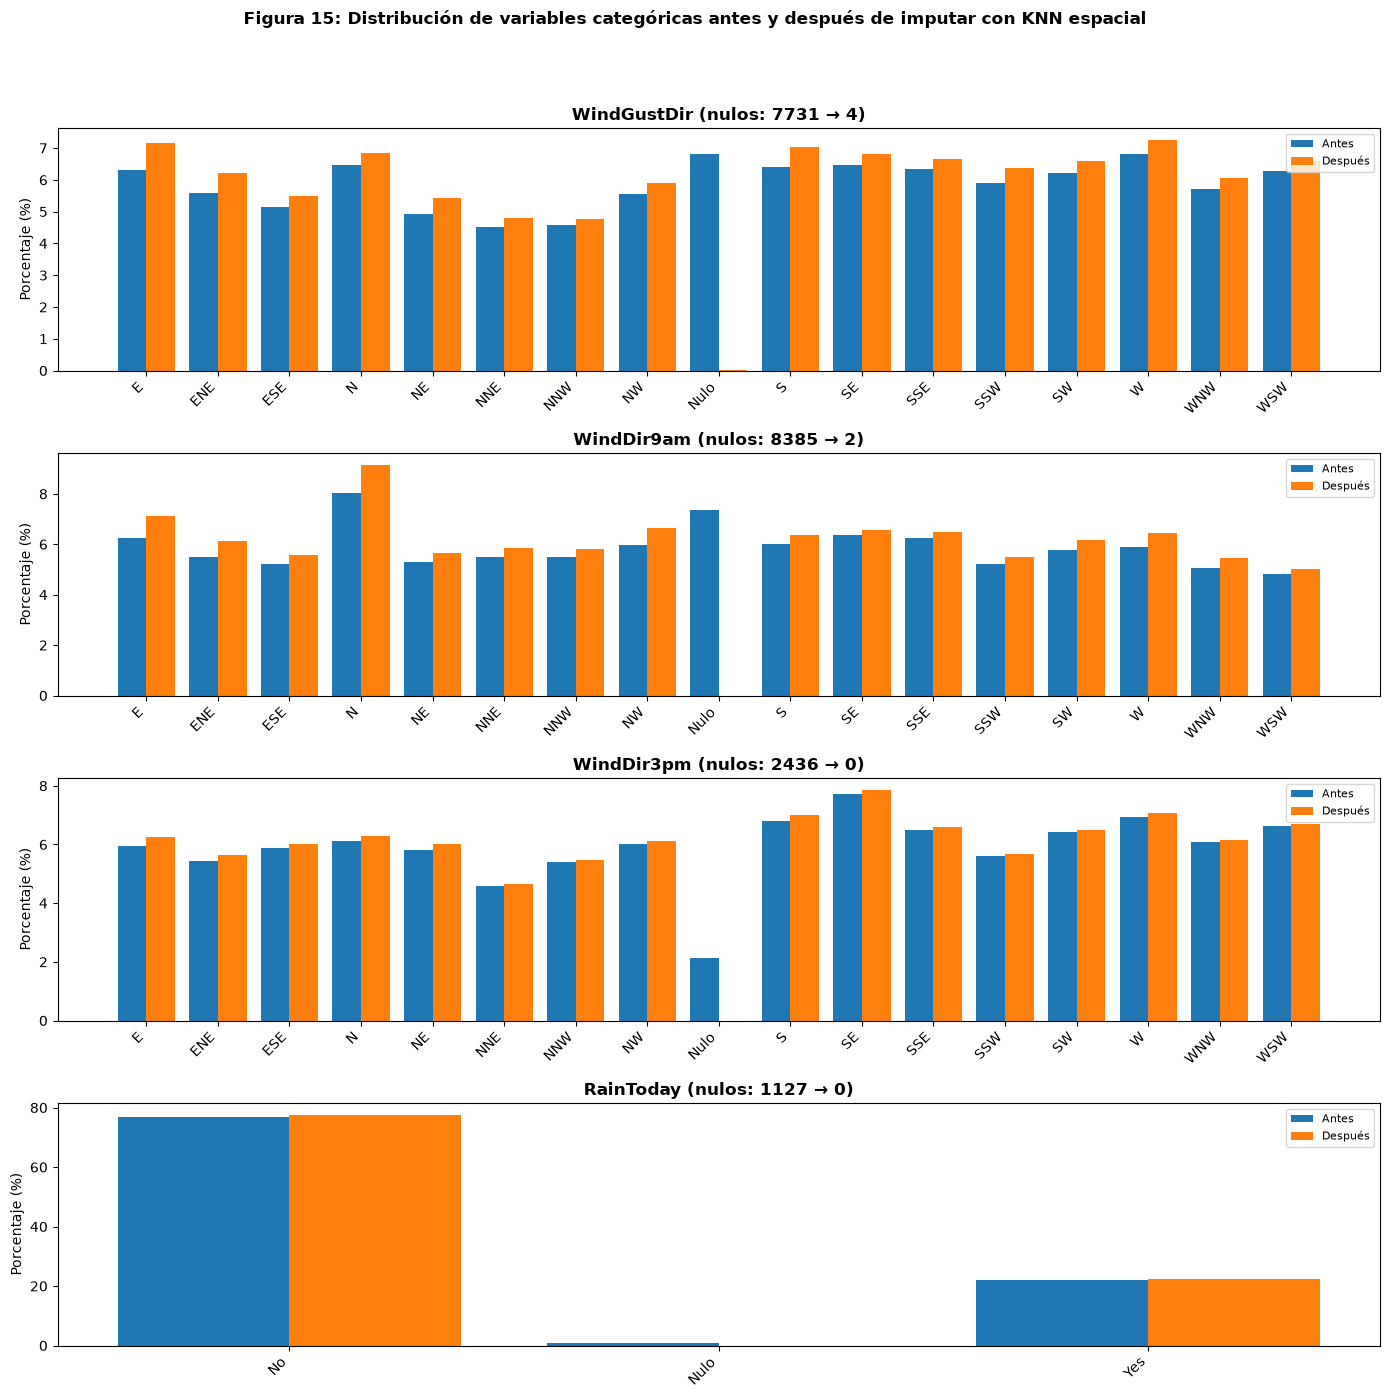

Train: 113,692 filas completas; test: 28,452 filas completas.


In [137]:
cols_cloud = ["Cloud9am", "Cloud3pm"]
K_VECINOS_ESPACIALES = 5
RADIO_TIERRA_KM = 6371.0088

mascara_cloud_train_knn = ~df_limpio.loc[train.index, cols_cloud].gt(8).any(axis=1)
mascara_cloud_test_knn = ~df_limpio.loc[test.index, cols_cloud].gt(8).any(axis=1)
train_knn = train.loc[mascara_cloud_train_knn & train["RainTomorrow"].notna()].copy()
test_knn = test.loc[mascara_cloud_test_knn & test["RainTomorrow"].notna()].copy()
y_train_knn = train_knn["RainTomorrow"].copy()
y_test_knn = test_knn["RainTomorrow"].copy()
X_train_knn = train_knn.drop(columns="RainTomorrow").copy()
X_test_knn = test_knn.drop(columns="RainTomorrow").copy()

if X_train_knn.duplicated(["Date", "Location"]).any() or X_test_knn.duplicated(["Date", "Location"]).any():
    raise ValueError("KNN espacial requiere una sola observación por fecha y localidad.")
if X_train_knn.columns.tolist() != X_test_knn.columns.tolist():
    raise AssertionError("Train y test deben tener las mismas variables para KNN espacial.")

localidades_knn = sorted(set(X_train_knn["Location"]) | set(X_test_knn["Location"]))
localidades_sin_coordenadas = set(localidades_knn) - set(coordenadas_localidades)
if localidades_sin_coordenadas:
    raise ValueError(f"Faltan coordenadas para: {sorted(localidades_sin_coordenadas)}")

coordenadas_radianes = np.radians(
    np.array([coordenadas_localidades[localidad] for localidad in localidades_knn], dtype=float)
)
latitudes = coordenadas_radianes[:, 0]
longitudes = coordenadas_radianes[:, 1]
delta_latitud = latitudes[None, :] - latitudes[:, None]
delta_longitud = longitudes[None, :] - longitudes[:, None]
a_haversine = (
    np.sin(delta_latitud / 2) ** 2
    + np.cos(latitudes[:, None]) * np.cos(latitudes[None, :])
    * np.sin(delta_longitud / 2) ** 2
)
distancias_km = 2 * RADIO_TIERRA_KM * np.arcsin(np.sqrt(np.clip(a_haversine, 0, 1)))
orden_estaciones_vecinas = {
    localidad: [
        localidades_knn[indice]
        for indice in np.argsort(distancias_km[posicion])
        if localidades_knn[indice] != localidad
    ]
    for posicion, localidad in enumerate(localidades_knn)
}
columnas_numericas_knn = set(X_train_knn.select_dtypes(include=[np.number]).columns)
columnas_imputar_knn = [
    columna for columna in X_train_knn.columns
    if columna not in {"Date", "Location"}
]

def imputar_knn_espacial(datos, columnas):
    resultado = datos.copy()
    reporte = []

    for columna in columnas:
        nulos_antes = int(resultado[columna].isna().sum())
        if columna not in columnas_numericas_knn:
            resultado[columna] = resultado[columna].astype(object)

        for _, grupo_dia in datos.groupby("Date", sort=False):
            faltantes = grupo_dia.loc[grupo_dia[columna].isna(), "Location"]
            if faltantes.empty:
                continue
            observados = grupo_dia.loc[
                grupo_dia[columna].notna(), ["Location", columna]
            ]
            donantes = dict(zip(observados["Location"], observados[columna]))
            localidades_disponibles = set(donantes)
            if not localidades_disponibles:
                continue

            for indice, localidad in faltantes.items():
                vecinos = [
                    vecina for vecina in orden_estaciones_vecinas[localidad]
                    if vecina in localidades_disponibles
                ][:K_VECINOS_ESPACIALES]
                if not vecinos:
                    continue

                valores_vecinos = [donantes[vecina] for vecina in vecinos]
                if columna in columnas_numericas_knn:
                    estimacion = float(np.median(valores_vecinos))
                    if columna in cols_cloud:
                        estimacion = round(estimacion)
                else:
                    estimacion = pd.Series(valores_vecinos, dtype="object").mode().iloc[0]
                resultado.at[indice, columna] = estimacion

        nulos_despues = int(resultado[columna].isna().sum())
        reporte.append({
            "Variable": columna,
            "Nulos antes": nulos_antes,
            "Imputados": nulos_antes - nulos_despues,
            "Nulos después": nulos_despues,
        })

    return resultado, pd.DataFrame(reporte)

reporte_validacion_knn = []
for columna in columnas_imputar_knn:
    observados = X_train_knn[columna].dropna()
    if observados.empty:
        continue
    ocultos_knn = observados.sample(frac=0.10, random_state=RANDOM_STATE).index
    datos_validacion_knn = X_train_knn[["Date", "Location", columna]].copy()
    datos_validacion_knn.loc[ocultos_knn, columna] = np.nan
    predicciones_knn, _ = imputar_knn_espacial(datos_validacion_knn, [columna])
    valores_predichos = predicciones_knn.loc[ocultos_knn, columna]
    valores_reales = X_train_knn.loc[ocultos_knn, columna]
    evaluables_knn = valores_predichos.notna()

    if columna in columnas_numericas_knn:
        metrica_knn = "MAE"
        resultado_knn = (
            (valores_predichos.loc[evaluables_knn].astype(float)
             - valores_reales.loc[evaluables_knn].astype(float)).abs().mean()
            if evaluables_knn.any() else np.nan
        )
    else:
        metrica_knn = "Exactitud"
        resultado_knn = (
            (valores_predichos.loc[evaluables_knn]
             == valores_reales.loc[evaluables_knn]).mean()
            if evaluables_knn.any() else np.nan
        )
    reporte_validacion_knn.append({
        "Variable": columna,
        "Métrica": metrica_knn,
        "Valores ocultados": len(ocultos_knn),
        "Casos evaluables": int(evaluables_knn.sum()),
        "Cobertura (%)": 100 * evaluables_knn.mean(),
        "Resultado": resultado_knn,
    })

X_train_knn_antes = X_train_knn.copy()
X_test_knn_antes = X_test_knn.copy()
X_train_knn_imputado, reporte_train_knn = imputar_knn_espacial(
    X_train_knn, columnas_imputar_knn
)
X_test_knn_imputado, reporte_test_knn = imputar_knn_espacial(
    X_test_knn, columnas_imputar_knn
)
reporte_validacion_knn = pd.DataFrame(reporte_validacion_knn)
reporte_imputacion_knn = pd.concat(
    [
        reporte_train_knn.assign(Conjunto="Train"),
        reporte_test_knn.assign(Conjunto="Test"),
    ],
    ignore_index=True,
)[["Conjunto", "Variable", "Nulos antes", "Imputados", "Nulos después"]]
display(reporte_validacion_knn.round(3))
display(reporte_imputacion_knn)

for columna in cols_cloud:
    for datos in [X_train_knn_imputado, X_test_knn_imputado]:
        if not datos[columna].dropna().between(0, 8).all():
            raise AssertionError(f"{columna} contiene valores fuera del dominio 0-8.")

columnas_numericas_grafico = [
    columna for columna in columnas_imputar_knn
    if columna in columnas_numericas_knn
]
columnas_categoricas_grafico = [
    columna for columna in columnas_imputar_knn
    if columna not in columnas_numericas_knn
]
n_columnas = 3
n_filas = int(np.ceil(len(columnas_numericas_grafico) / n_columnas))
fig, axes = plt.subplots(n_filas, n_columnas, figsize=(18, 4 * n_filas))
axes = np.asarray(axes).reshape(-1)
for ax, columna in zip(axes, columnas_numericas_grafico):
    antes = X_train_knn_antes[columna].dropna().astype(float)
    despues = X_train_knn_imputado[columna].dropna().astype(float)
    valores = pd.concat([antes, despues], ignore_index=True)
    bins = np.arange(-0.5, 9.5, 1) if columna in cols_cloud else np.histogram_bin_edges(valores, bins=30)
    ax.hist(antes, bins=bins, density=True, histtype="step", linewidth=1.5, label="Antes")
    ax.hist(despues, bins=bins, density=True, histtype="step", linewidth=1.5, label="Después")
    ax.set_title(f"{columna} (nulos: {X_train_knn_antes[columna].isna().sum()} → {X_train_knn_imputado[columna].isna().sum()})", fontweight="bold")
    ax.set_ylabel("Proporción")
    ax.legend(fontsize=8)
for ax in axes[len(columnas_numericas_grafico):]:
    ax.set_visible(False)
fig.suptitle(f"Figura {N_FIG}: Distribución de variables numéricas antes y después de imputar con KNN espacial", y=0.995, fontweight="bold")
N_FIG += 1
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

if columnas_categoricas_grafico:
    fig, axes = plt.subplots(
        len(columnas_categoricas_grafico), 1,
        figsize=(14, max(4, 3.5 * len(columnas_categoricas_grafico))),
    )
    axes = np.atleast_1d(axes)
    for ax, columna in zip(axes, columnas_categoricas_grafico):
        antes = X_train_knn_antes[columna].fillna("Nulo").astype(str)
        despues = X_train_knn_imputado[columna].fillna("Nulo").astype(str)
        categorias = pd.Index(antes.unique()).union(pd.Index(despues.unique()))
        pct_antes = antes.value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
        pct_despues = despues.value_counts(normalize=True).reindex(categorias, fill_value=0) * 100
        posiciones = np.arange(len(categorias))
        ax.bar(posiciones - 0.2, pct_antes, width=0.4, label="Antes")
        ax.bar(posiciones + 0.2, pct_despues, width=0.4, label="Después")
        ax.set_xticks(posiciones, categorias, rotation=45, ha="right")
        ax.set_ylabel("Porcentaje (%)")
        ax.set_title(f"{columna} (nulos: {X_train_knn_antes[columna].isna().sum()} → {X_train_knn_imputado[columna].isna().sum()})", fontweight="bold")
        ax.legend(fontsize=8)
    fig.suptitle(f"Figura {N_FIG}: Distribución de variables categóricas antes y después de imputar con KNN espacial", y=0.995, fontweight="bold")
    N_FIG += 1
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

mascara_train_knn_completo = X_train_knn_imputado[columnas_imputar_knn].notna().all(axis=1)
mascara_test_knn_completo = X_test_knn_imputado[columnas_imputar_knn].notna().all(axis=1)
X_train = X_train_knn_imputado.loc[mascara_train_knn_completo].copy()
X_test = X_test_knn_imputado.loc[mascara_test_knn_completo].copy()
y_train = y_train_knn.loc[mascara_train_knn_completo].copy()
y_test = y_test_knn.loc[mascara_test_knn_completo].copy()

if not X_train.index.equals(y_train.index) or not X_test.index.equals(y_test.index):
    raise AssertionError("Los predictores y objetivos quedaron desalineados tras imputar.")
print(f"Train: {len(X_train):,} filas completas; test: {len(X_test):,} filas completas.")

La imputación espacial estima cada faltante con las cinco estaciones disponibles más cercanas para esa misma fecha, y la validación oculta el 10 % de los valores observados de train. La cobertura de los casos evaluables ronda el 99,7–99,9 %. Los MAE dependen de la unidad: son 1,82–1,92 para presión, 2,42–2,86 para temperatura y 11,88–12,97 para humedad. La exactitud de las direcciones del viento es baja, entre 18 % y 20 %, mientras que RainToday alcanza 0,841. Tras imputar quedan en train 4 nulos en WindGustDir, 2 en WindGustSpeed y 2 en WindDir9am, que se eliminan para completar los datos.

## 12. Conservación de valores atípicos

No eliminamos observaciones solo por ser atípicas según una regla estadística. En datos meteorológicos, valores extremos pueden representar fenómenos reales y aportar información importante para predecir lluvia. Como no identificamos evidencia de que esos valores sean errores de carga o medición, los conservamos.

## 13. Balance de la variable objetivo

Verificamos la distribución de `RainTomorrow` en train después de la limpieza final. Si las clases están desbalanceadas, conservamos su proporción observada en lugar de sobremuestrear o submuestrear: así evitamos alterar artificialmente la distribución de los datos. Durante el modelado ajustaremos el umbral de decisión usando validación y una métrica adecuada para el objetivo; el conjunto de test se reserva para la evaluación final y no se usa para elegir ese umbral.

,Conjunto,Clase,Cantidad,Porcentaje (%),Relación mayoritaria/minoritaria
0,Train,No,88168,77.55,3.45
1,Train,Yes,25524,22.45,3.45


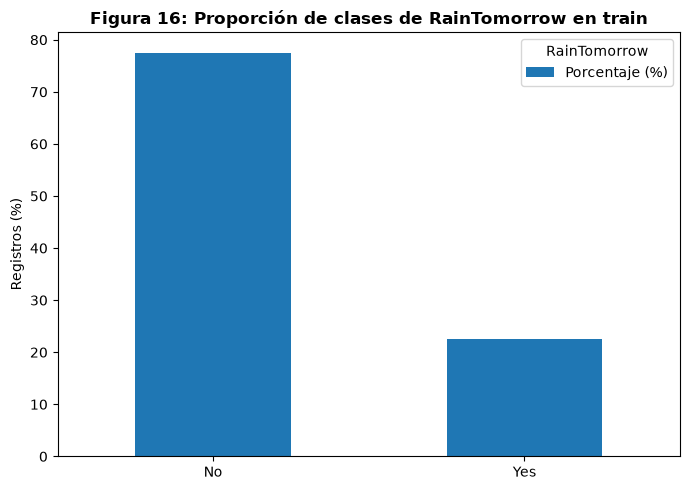

Train: la clase Yes representa 22.45% de los casos; la clase mayoritaria aparece 3.45 veces más que la minoritaria.


In [138]:
clases_objetivo = ["No", "Yes"]
reporte_balance = []
for nombre, objetivo in [("Train", y_train)]:
    clases_inesperadas = set(objetivo.dropna().unique()) - set(clases_objetivo)
    if clases_inesperadas:
        raise ValueError(f"Clases inesperadas en {nombre}: {clases_inesperadas}")
    conteos = objetivo.value_counts().reindex(clases_objetivo, fill_value=0)
    proporciones = objetivo.value_counts(normalize=True).reindex(clases_objetivo, fill_value=0) * 100
    minoritaria = conteos.min()
    relacion_desbalance = conteos.max() / minoritaria if minoritaria else np.nan
    for clase in clases_objetivo:
        reporte_balance.append({
            "Conjunto": nombre,
            "Clase": clase,
            "Cantidad": int(conteos[clase]),
            "Porcentaje (%)": proporciones[clase],
            "Relación mayoritaria/minoritaria": relacion_desbalance,
        })

reporte_balance = pd.DataFrame(reporte_balance)
display(reporte_balance.round(2))

proporciones_grafico = reporte_balance.set_index("Clase")["Porcentaje (%)"].reindex(clases_objetivo)
ax = proporciones_grafico.plot(kind="bar", figsize=(7, 5), rot=0)
ax.set_title(f"Figura {N_FIG}: Proporción de clases de RainTomorrow en train", fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Registros (%)")
ax.legend(title="RainTomorrow")
plt.tight_layout()
plt.show()
N_FIG += 1

yes_train = reporte_balance.query("Conjunto == 'Train' and Clase == 'Yes'")["Porcentaje (%)"].iloc[0]
ratio_train = reporte_balance.query("Conjunto == 'Train'")["Relación mayoritaria/minoritaria"].iloc[0]
print(
    f"Train: la clase Yes representa {yes_train:.2f}% de los casos; "
    f"la clase mayoritaria aparece {ratio_train:.2f} veces más que la minoritaria."
)


La salida de balance final contiene 88.168 casos No y 25.524 Yes: 77,55 % frente a 22,45 %, con una relación de 3,45 a 1. Se conserva esta distribución sin sobremuestrear ni submuestrear, para no modificar artificialmente las proporciones observadas. Si se necesita otro compromiso entre errores, el umbral debe ajustarse con validación y no con el conjunto de test.

## 14. Codificación de variables cualitativas y cíclicas

Reemplazamos `Location` por coordenadas geográficas aproximadas de cada localidad (no necesariamente la posición exacta de cada estación meteorológica), en grados decimales. A partir de `Date` creamos seno y coseno del mes para representar la continuidad entre diciembre y enero. Las tres direcciones del viento se convierten a ángulos de brújula y luego a seno y coseno, conservando su naturaleza cíclica. `RainToday` se codifica como 0 (No) y 1 (Yes). Aplicamos las mismas reglas a train y test y quitamos las columnas originales que ya quedaron representadas numéricamente.

In [139]:
direcciones_viento = ["WindGustDir", "WindDir9am", "WindDir3pm"]
angulos_viento = {
    direccion: angulo
    for direccion, angulo in zip(
        ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
         "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"],
        np.arange(0, 360, 22.5),
    )
}

def codificar_predictores(datos):
    codificados = datos.copy()
    localidades_desconocidas = set(codificados["Location"].dropna().unique()) - set(coordenadas_localidades)
    if localidades_desconocidas:
        raise ValueError(f"Faltan coordenadas para estas localidades: {sorted(localidades_desconocidas)}")
    if codificados["Location"].isna().any():
        raise ValueError("Hay localidades nulas antes de asignar coordenadas.")

    coordenadas = codificados["Location"].map(coordenadas_localidades)
    codificados["Latitud"] = coordenadas.map(lambda valor: valor[0])
    codificados["Longitud"] = coordenadas.map(lambda valor: valor[1])

    mes = codificados["Date"].dt.month
    codificados["Mes_sin"] = np.sin(2 * np.pi * (mes - 1) / 12)
    codificados["Mes_cos"] = np.cos(2 * np.pi * (mes - 1) / 12)

    for columna in direcciones_viento:
        angulos = codificados[columna].map(angulos_viento)
        if angulos.isna().any():
            valores_invalidos = codificados.loc[angulos.isna(), columna].dropna().unique().tolist()
            if valores_invalidos or codificados[columna].isna().any():
                raise ValueError(f"Valores de dirección no reconocidos en {columna}: {valores_invalidos}")
        radianes = np.deg2rad(angulos)
        codificados[f"{columna}_sin"] = np.sin(radianes)
        codificados[f"{columna}_cos"] = np.cos(radianes)

    valores_rain_today = set(codificados["RainToday"].dropna().unique())
    if not valores_rain_today.issubset({"No", "Yes"}) or codificados["RainToday"].isna().any():
        raise ValueError(f"Valores no esperados en RainToday: {sorted(valores_rain_today)}")
    codificados["RainToday"] = codificados["RainToday"].map({"No": 0, "Yes": 1}).astype("int8")

    columnas_originales = ["Date", "Location", *direcciones_viento]
    codificados = codificados.drop(columns=columnas_originales)
    if codificados.isna().any().any():
        raise ValueError("La codificación generó o dejó valores nulos en los predictores.")
    columnas_no_numericas = codificados.select_dtypes(exclude=[np.number]).columns.tolist()
    if columnas_no_numericas:
        raise TypeError(f"Quedaron columnas no numéricas tras codificar: {columnas_no_numericas}")
    return codificados

X_train = codificar_predictores(X_train)
X_test = codificar_predictores(X_test)
if X_train.columns.tolist() != X_test.columns.tolist():
    raise AssertionError("Train y test no tienen las mismas columnas después de codificar.")

display(pd.DataFrame({
    "Variable codificada": X_train.columns,
    "Tipo": X_train.dtypes.astype(str).values,
}).reset_index(drop=True))
print(f"Dimensiones codificadas: train {X_train.shape}; test {X_test.shape}.")

,Variable codificada,Tipo
0,MinTemp,float64
1,MaxTemp,float64
2,Rainfall,float64
3,Evaporation,float64
4,Sunshine,float64
5,WindGustSpeed,float64
6,WindSpeed9am,float64
7,WindSpeed3pm,float64
8,Humidity9am,float64
9,Humidity3pm,float64


Dimensiones codificadas: train (113692, 24); test (28452, 24).


La codificación reemplaza Location por coordenadas aproximadas, representa el mes y las direcciones del viento mediante seno y coseno para conservar su continuidad cíclica, y convierte RainToday en una variable binaria. Después de estas transformaciones, train y test tienen únicamente valores numéricos y dimensiones de 113.692 por 27 y 28.452 por 27, respectivamente.

## 15. Escalado con RobustScaler

Antes del escalado aplicamos `log1p` a `Rainfall` y `Evaporation`, variables no negativas con cola derecha marcada. `log1p(x)` equivale a log(1+x), admite ceros y reduce la influencia de valores extremos sin eliminarlos. Luego escalamos las variables meteorológicas continuas y las coordenadas con `RobustScaler`, que centra por la mediana y divide por el rango intercuartílico. El escalador se ajusta solo con train y se aplica a test. Conservamos la versión codificada original, la versión con logaritmo y la versión escalada; `RainToday` y los pares seno/coseno quedan sin escalar. Los boxplots muestran por separado el efecto de `log1p` en las dos variables y la comparación general antes/después del escalado.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\2635195853.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\2635195853.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\2635195853.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Usuario\AppData\Local\Temp\ipykernel_21752\2635195853.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


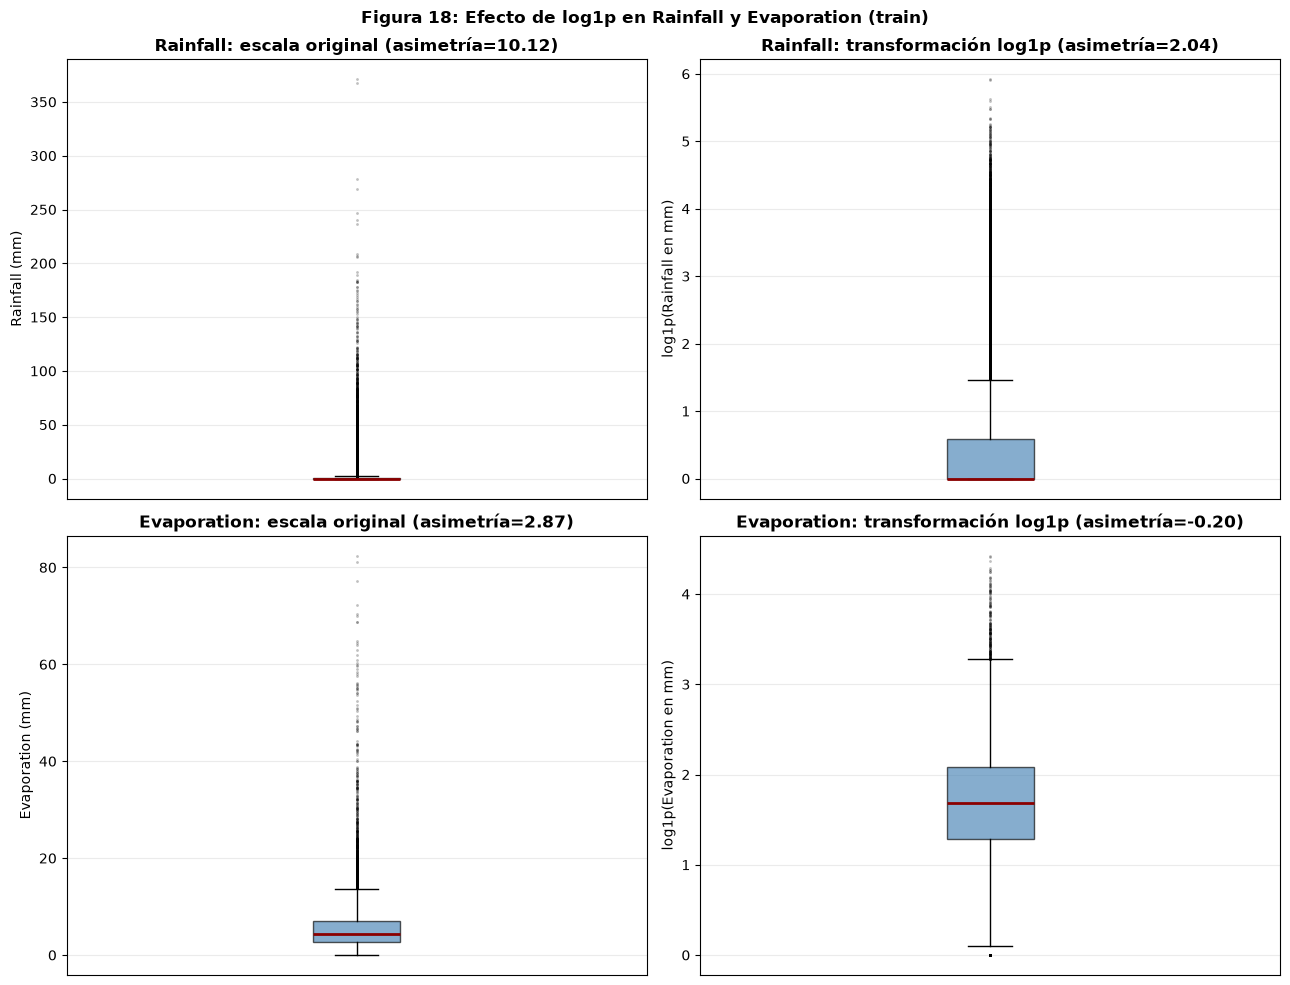

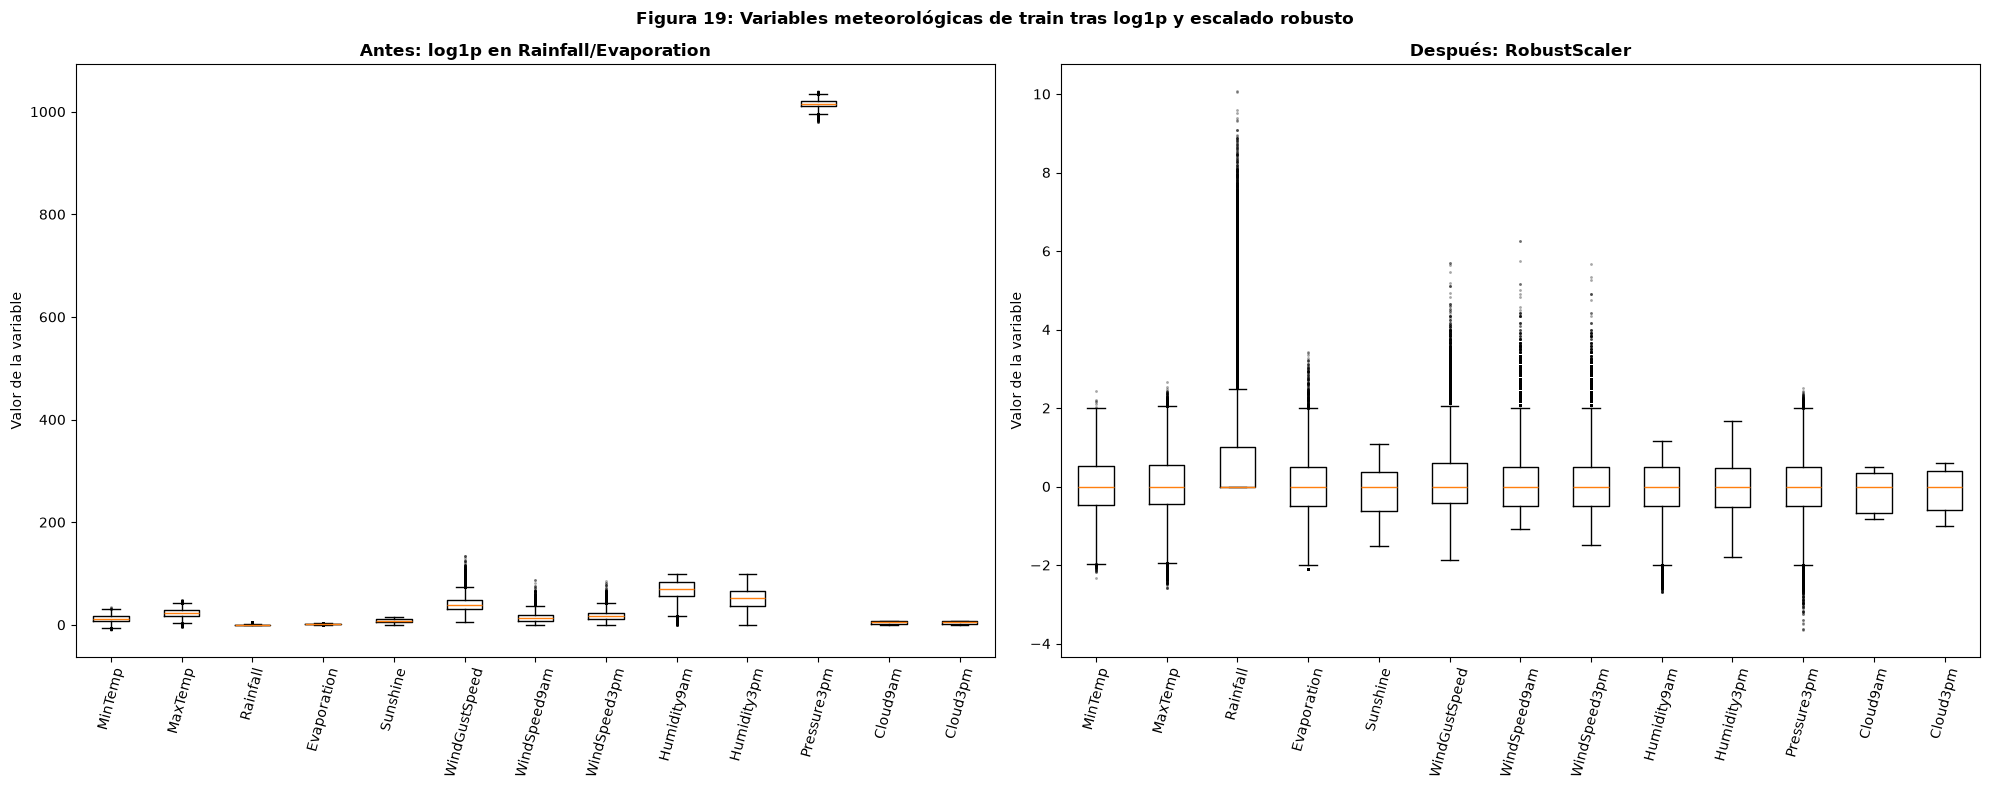

Transformación log1p aplicada a: ['Rainfall', 'Evaporation'].
Versiones conservadas: codificadas (113692, 24)/(28452, 24); con log1p (113692, 24)/(28452, 24); escaladas (113692, 24)/(28452, 24).
El escalador se ajusta solo con train; X_train_codificado y X_test_codificado conservan los valores sin transformar.


In [141]:
from sklearn.preprocessing import RobustScaler

X_train_codificado = X_train.copy()
X_test_codificado = X_test.copy()
if X_train_codificado.columns.tolist() != X_test_codificado.columns.tolist():
    raise AssertionError("Train y test deben tener las mismas columnas antes de escalar.")
if X_train_codificado.isna().any().any() or X_test_codificado.isna().any().any():
    raise ValueError("No se puede escalar: hay valores nulos en train o test.")
if not all(pd.api.types.is_numeric_dtype(tipo) for tipo in X_train_codificado.dtypes):
    raise TypeError("RobustScaler requiere que todas las variables estén codificadas numéricamente.")

columnas_log = ["Rainfall", "Evaporation"]
columnas_faltantes_log = set(columnas_log) - set(X_train_codificado.columns)
if columnas_faltantes_log:
    raise KeyError(f"No se encontraron las variables para transformar: {sorted(columnas_faltantes_log)}")
for conjunto_nombre, conjunto in [("train", X_train_codificado), ("test", X_test_codificado)]:
    if (conjunto[columnas_log] < 0).any().any():
        raise ValueError(f"log1p requiere valores no negativos en Rainfall y Evaporation ({conjunto_nombre}).")

X_train_log = X_train_codificado.copy()
X_test_log = X_test_codificado.copy()
for columna in columnas_log:
    X_train_log[columna] = np.log1p(X_train_codificado[columna])
    X_test_log[columna] = np.log1p(X_test_codificado[columna])

columnas_sin_escalar = {
    "RainToday", "Mes_sin", "Mes_cos",
    "WindGustDir_sin", "WindGustDir_cos",
    "WindDir9am_sin", "WindDir9am_cos",
    "WindDir3pm_sin", "WindDir3pm_cos",
}
columnas_escalar_robusto = [
    col for col in X_train_log.columns if col not in columnas_sin_escalar
]
escalador_robusto = RobustScaler()
X_train_robust = X_train_log.copy()
X_test_robust = X_test_log.copy()
X_train_robust[columnas_escalar_robusto] = escalador_robusto.fit_transform(
    X_train_log[columnas_escalar_robusto]
)
X_test_robust[columnas_escalar_robusto] = escalador_robusto.transform(
    X_test_log[columnas_escalar_robusto]
)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for fila, columna in enumerate(columnas_log):
    valores_originales = X_train_codificado[columna].dropna().to_numpy()
    valores_log = X_train_log[columna].dropna().to_numpy()
    asimetria_original = X_train_codificado[columna].skew()
    asimetria_log = X_train_log[columna].skew()
    for ax, valores, titulo, asimetria, etiqueta_y in [
        (axes[fila, 0], valores_originales, f"{columna}: escala original", asimetria_original, f"{columna} (mm)"),
        (axes[fila, 1], valores_log, f"{columna}: transformación log1p", asimetria_log, f"log1p({columna} en mm)"),
    ]:
        ax.boxplot(
            valores,
            vert=True,
            patch_artist=True,
            boxprops={"facecolor": "steelblue", "alpha": 0.65},
            medianprops={"color": "darkred", "linewidth": 2},
            showfliers=True,
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.25},
        )
        ax.set_title(f"{titulo} (asimetría={asimetria:.2f})", fontweight="bold")
        ax.set_ylabel(etiqueta_y)
        ax.set_xticks([])
        ax.grid(axis="y", alpha=0.25)
fig.suptitle(f"Figura {N_FIG}: Efecto de log1p en Rainfall y Evaporation (train)", fontweight="bold")
N_FIG += 1
plt.tight_layout()
plt.show()

variables_meteorologicas_boxplot = [
    col for col in X_train_log.columns
    if col not in {
        "Latitud", "Longitud", "Mes_sin", "Mes_cos", "RainToday",
        "WindGustDir_sin", "WindGustDir_cos",
        "WindDir9am_sin", "WindDir9am_cos",
        "WindDir3pm_sin", "WindDir3pm_cos",
    }
]
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, datos, titulo in [
    (axes[0], X_train_log, "Antes: log1p en Rainfall/Evaporation"),
    (axes[1], X_train_robust, "Después: RobustScaler"),
]:
    ax.boxplot(
        [datos[col].dropna().to_numpy() for col in variables_meteorologicas_boxplot],
        tick_labels=variables_meteorologicas_boxplot,
        showfliers=True,
        flierprops={"marker": ".", "markersize": 2, "alpha": 0.35},
    )
    ax.set_title(titulo, fontweight="bold")
    ax.tick_params(axis="x", rotation=75)
    ax.set_ylabel("Valor de la variable")
fig.suptitle(f"Figura {N_FIG}: Variables meteorológicas de train tras log1p y escalado robusto", fontweight="bold")
plt.tight_layout()
plt.show()
N_FIG += 1

print(f"Transformación log1p aplicada a: {columnas_log}.")
print(f"Versiones conservadas: codificadas {X_train_codificado.shape}/{X_test_codificado.shape}; con log1p {X_train_log.shape}/{X_test_log.shape}; escaladas {X_train_robust.shape}/{X_test_robust.shape}.")
print("El escalador se ajusta solo con train; X_train_codificado y X_test_codificado conservan los valores sin transformar.")

En los valores observados del train antes de imputar, Rainfall tiene asimetría 10,13 y Evaporation 3,25. Aplicar log1p reduce sus colas derechas y mantiene los ceros; el boxplot actualizado informa también la asimetría en los datos finales. No aplicamos logaritmo a las velocidades del viento: su asimetría es moderada (0,60–0,86) y log1p la vuelve negativa (aproximadamente -0,28 a -1,47). Después de transformar Rainfall y Evaporation, RobustScaler se ajusta únicamente con train y se aplica a test. Se conservan las versiones originales, transformadas y escaladas; los boxplots específicos comparan ambas variables antes y después de log1p sin que otras unidades las compriman.